<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px; box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1);">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin: 0; font-size: 2.2em; letter-spacing: -0.5px;">Índice de Compromiso y Competencia</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;">Estudio del tiempo de deberes, el absentismo y la impuntualidad a través de los estratos fijos</p>
</div>

# 1. Descripción y Configuración Metodológica

En este cuaderno se construye el **índice de compromiso y competencia** a partir de tres comportamientos observables y reproducibles en las cuatro ediciones de PISA (2012, 2015, 2018 y 2022): el **tiempo diario dedicado a los deberes**, el **absentismo** (`SKIPPING`) y la **impuntualidad** (`TARDYSD`). Como paso previo, contrastamos en 2022 la hipótesis: *"Asignar más horas de deberes es sinónimo de obtener mejores resultados en Matemáticas en el contexto del estrato fijo escolar"*.

El análisis se estructura sobre dos niveles:

1. **Nivel Alumno con Estrato Fijo (`CNT`, `CNTSCHID`, `CNTSTUID`, `PERFIL_CODE`):** Los indicadores de compromiso individual se recalculan y se cruzan directamente con los **estratos** generados en etapas previas (`data/intermediate/estratos_fijos`), aislando las características del centro respecto al comportamiento personal del alumno.

2. **Nivel País (`CNT`):** Vista macro agregada de forma ponderada (`W_FSTUWT`) a nivel nacional para contrastar la Paradoja de los estratos y auditar la cobertura longitudinal (2012–2022).

## 1.1 Selección de las variables del índice de compromiso y competencia

💡 **¿por qué no usamos un modelo para seleccionar las variables ni utilizamos escalas psicométricas?**

En lugar de entrenar un modelo exploratorio que ordene variables candidatas por importancia, seleccionamos las variables **a priori** con un criterio de comparabilidad entre las diferentes ediciones:

* **Descartamos las escalas psicométricas subjetivas.** Los índices actitudinales se estiman con baterías de ítems distintas en cada edición, por lo que su medida cambia entre ciclos y no son comparables en el tiempo.

* **Nos quedamos con comportamientos cuantitativos y observables.** Las tres variables elegidas describen conductas cuantitativas (horas de estudio, faltas y retrasos) que se preguntan de forma equivalente en todas las ediciones de este estudio.

* **Un criterio teórico es más estable que uno empírico.** Una selección por importancia en un único año depende del dominio principal de ese ciclo y no garantiza continuidad en los demás.

Las tres variables que conforman el **índice de compromiso y competencia**, junto con las claves de cruce y los pesos muestrales, son:

| Código de variable | Nombre | Tipo | Descripción y tratamiento metodológico |
| :--- | :--- | :--- | :--- |
| `ST296Q04JA` (2022) | `tiempo_deberes_totales_diarios` | Continua $[0, 4.50]$ h | Tiempo total diario dedicado a deberes; armonizado en cada edición según la lógica de las Secciones 1.5 y 4; entra en el índice puntuado en U invertida por terciles (Sección 5.6.2). |
| `SKIPPING` | Absentismo escolar | Dicotómica (0 / 1) | Haber faltado a un día entero o a clases sueltas en las dos últimas semanas. |
| `TARDYSD` | Impuntualidad | Ordinal (0 / 1 / 2) | Frecuencia con la que el alumno ha llegado tarde al colegio en las dos últimas semanas. |
| `PERFIL_CODE`, `PERFIL_DESC` | `estrato_fijo_escolar` | Categórica | Estrato fijo institucional del centro educativo (Titularidad, Ubicación y Tamaño `SCHSIZE`). |
| `W_FSTUWT`, `SENWT` | Pesos muestrales | Continua | Peso final poblacional del alumno (`W_FSTUWT`) y peso de senado (`SENWT`) para agregaciones y modelado ponderado. |

## 1.2 Tabla de equivalencias inter-edición (Crosswalk) de los indicadores de asistencia

Los ítems de asistencia del cuestionario del alumno mantienen el mismo enunciado y las mismas opciones de respuesta en las cuatro ediciones; solo cambia su código entre 2012 y el resto de ciclos:

| Fenómeno Evaluado | PISA 2012 | PISA 2015 | PISA 2018 | PISA 2022 | Opciones de Respuesta en el Cuestionario |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Faltar un día entero de colegio** | `ST09Q01` | `ST062Q01TA` | `ST062Q01TA` | `ST062Q01TA` | `1` = Ninguna vez (*Never*) <br> `2` = 1 o 2 veces <br> `3` = 3 o 4 veces <br> `4` = 5 o más veces |
| **Saltarse clases sueltas** | `ST115Q01` | `ST062Q02TA` | `ST062Q02TA` | `ST062Q02TA` | Idénticas a la variable anterior |
| **Llegar tarde al colegio** | `ST08Q01` | `ST062Q03TA` | `ST062Q03TA` | `ST062Q03TA` | Idénticas a la variable anterior |

## 1.3 Lógica oficial de codificación de los índices derivados (OCDE)

Los dos índices de asistencia se derivan de los ítems anteriores con la siguiente regla oficial de la OCDE:

1. **`SKIPPING` (Índice Dicotómico de Absentismo Escolar):**
   - `0`: El estudiante indica *"Ninguna vez"* tanto en faltar días completos como en saltarse clases sueltas.
   - `1`: El estudiante indica haber faltado al menos una vez (1 o más veces) a un día completo o a una clase suelta en las últimas dos semanas.
2. **`TARDYSD` (Índice Categorizado de Impuntualidad):**
   - `0`: Alumno puntual (*"Ninguna vez"* en llegar tarde).
   - `1`: Impuntualidad ocasional (llegó tarde *1 o 2 veces*).
   - `2`: Impuntualidad frecuente (llegó tarde *3 o más veces*).

💡 **Disponibilidad por edición y tratamiento de respuestas parciales**

* **PISA 2022** publica `SKIPPING` y `TARDYSD` ya calculados. En **2012, 2015 y 2018** no existen, por lo que los construimos con exactamente la misma regla a partir de los ítems base del Crosswalk.
* **Respuestas parciales en `SKIPPING`:** el índice `SKIPPING` solo queda como valor faltante si el alumno no responde a ninguno de los dos ítems. Si responde a uno, se calcula con la información disponible. Es el comportamiento de los datos oficiales de 2022, que verificamos fila a fila en la Sección 1.5.1.

## 1.4 Carga de librerías, microdatos de 2022 y cruce con estratos fijos

Cargamos los datos de estudiantes para la edicion de **PISA 2022** que servirá de base para el análisis y el fichero de estratos `pisa2022_estratos_fijos.parquet` con los estratos generados anteriormente.

In [88]:
import gc
import sys
import os
from pathlib import Path

sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import pyarrow.parquet as pq
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
# Matriz waffle apaisada de disponibilidad: países en columnas y (Variable, Edición) en filas
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.lines import Line2D

from src.utils_pisa import *
from src.pisa_estadisticas import agregar_media_ponderada
from src.pisa_pipeline import rutas_datos_anuales, columnas_pv

# Configuración global de semilla y formato numérico
establecer_semilla(42)
pd.set_option('display.float_format', lambda valor: f'{valor:.2f}')

Semillas del proyecto establecidas con éxito (seed=42).


In [89]:
# Definición de rutas de entrada y salida del flujo de compromiso escolar
RUTA_DATOS_RAW = Path('../../data/raw')
RUTA_DATOS_ANUALES = Path('../../data/raw/datos_anuales')
RUTA_INTERMEDIOS = Path('../../data/intermediate')
RUTA_ESTRATOS = RUTA_INTERMEDIOS / 'estratos_fijos'
RUTA_PROCESADOS = Path('../../data/processed')
RUTA_ASIGNATURAS = RUTA_INTERMEDIOS / 'medias_asignaturas_anual'

# Carpeta de salida con un fichero del índice de compromiso y competencia por edición
RUTA_SALIDA_COMPROMISO_COMPETENCIA = RUTA_INTERMEDIOS / 'compromiso_competencia'

In [90]:
# Claves de identificación y pesos muestrales del alumno
claves_pais = ['CNT']
claves_alumno = ['CNT', 'CNTSTUID']
claves_colegio = ['CNT', 'CNTSCHID']
claves_estrato_union = ['CNT', 'CNTSCHID', 'CNTSTUID']
columnas_pesos = ['W_FSTUWT', 'SENWT']

# Variables que se leen en 2022: tramos de deberes (ST296) e índices oficiales de asistencia
indicadores_alumno = [
    'ST296Q01JA',
    'ST296Q04JA',
    'SKIPPING',
    'TARDYSD',
]

# Ítems base de asistencia en 2022 (solo se usan para validar la regla oficial)
items_asistencia_2022 = ['ST062Q01TA', 'ST062Q02TA', 'ST062Q03TA']

# Las 3 variables que conforman el índice de compromiso y competencia en 2022
indicadores_compromiso = ['ST296Q04JA', 'SKIPPING', 'TARDYSD']

# Diccionario descriptivo para tablas y gráficos
diccionario_indicadores = {
    'PV1MATH': 'Nota Matemáticas (Alumno - PV1)',
    'media_math_pais': 'Nota Media Matemáticas (País)',
    'ST296Q01JA': 'Horas deberes Matemáticas (diarias)',
    'ST296Q04JA': 'Horas totales deberes (diarias)',
    'tiempo_deberes_totales_diarios': 'Horas totales deberes (diarias)',
    'SKIPPING': 'Absentismo (0 = No, 1 = Sí)',
    'TARDYSD': 'Impuntualidad (0 = Nunca, 1 = 1-2 veces, 2 = 3 o más)',
}

In [91]:
# Funciones de derivación de los índices de asistencia según la regla oficial de la OCDE

def construir_skipping(serie_dia_completo, serie_clases_sueltas):
    """
    Índice de absentismo (SKIPPING).
    0 = 'Ninguna vez' en los dos ítems | 1 = al menos una falta en alguno de ellos.
    Solo queda como NaN cuando faltan las dos respuestas.
    """
    # Un código superior a 1 equivale a haber faltado 1 o más veces
    ha_faltado = (serie_dia_completo > 1) | (serie_clases_sueltas > 1)
    skipping = ha_faltado.astype(float)

    # Sin ninguna de las dos respuestas no es posible calcular el índice
    sin_respuesta = serie_dia_completo.isna() & serie_clases_sueltas.isna()
    skipping[sin_respuesta] = np.nan

    return skipping


def construir_tardysd(serie_llegar_tarde):
    """
    Índice categorizado de impuntualidad (TARDYSD).
    0 = puntual | 1 = 1 o 2 veces | 2 = 3 o más veces.
    """
    # Los códigos 3 ('3 o 4 veces') y 4 ('5 o más veces') se agrupan como impuntualidad frecuente
    mapeo_tardysd = {1: 0.0, 2: 1.0, 3: 2.0, 4: 2.0}

    return serie_llegar_tarde.map(mapeo_tardysd)

In [92]:
# Rutas de estudiantes y estratos fijos para la edición de referencia 2022
ruta_est_2022 = RUTA_DATOS_ANUALES / 'pisa2022_estudiantes.parquet'
ruta_estratos_2022 = RUTA_ESTRATOS / 'pisa2022_estratos_fijos.parquet'

# Detección automática del primer Plausible Value de Matemáticas disponible en 2022 (PV1MATH)
nombres_pv_mates = set(columnas_pv('MATH'))
columnas_pv_edicion = [
    columna
    for columna in pq.read_schema(ruta_est_2022).names
    if columna in nombres_pv_mates
]
col_pv_math = columnas_pv_edicion[0]

In [93]:
# Lectura de microdatos de estudiantes, estratos fijos y media nacional de Matemáticas en 2022
cols_lectura_est = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + [col_pv_math]
    + indicadores_alumno + items_asistencia_2022
))

df_estudiantes_2022 = pd.read_parquet(
    ruta_est_2022,
    columns=cols_lectura_est
)

df_estratos_2022 = pd.read_parquet(ruta_estratos_2022)

df_notas_mates_pais_2022 = pd.read_parquet(
    RUTA_ASIGNATURAS / 'pisa_medias_asignaturas_pais_anual.parquet',
    columns=claves_pais + ['media_math_pais', 'year']
).query('year == 2022')

print(f"Alumnos leídos en 2022: {len(df_estudiantes_2022):,}")
print(f"Alumnos con estrato fijo asignado en 2022: {len(df_estratos_2022):,}")
print(f"Países en media nacional 2022: {len(df_notas_mates_pais_2022):,}")

display(df_estudiantes_2022.head())
display(df_estratos_2022.head())

Alumnos leídos en 2022: 268,610
Alumnos con estrato fijo asignado en 2022: 186,094
Países en media nacional 2022: 33


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,SKIPPING,TARDYSD,ST062Q01TA,ST062Q02TA,ST062Q03TA
0,AUS,3600001,3600477,21.49,0.41,447.45,2.00,2.00,0.00,0.00,1.00,1.00,1.00
1,AUS,3600002,3600016,26.35,0.50,581.64,3.00,5.00,1.00,0.00,2.00,1.00,1.00
2,AUS,3600004,3600669,34.43,0.65,349.95,4.00,5.00,1.00,1.00,2.00,3.00,2.00
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AUS,3600008,3600325,8.86,0.17,363.51,1.00,1.00,1.00,1.00,1.00,2.00,2.00


,CNT,CNTSCHID,CNTSTUID,PERFIL_CODE,PERFIL_DESC
0,AUS,3600477,3600001,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto
1,AUS,3600016,3600002,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto
2,AUS,3600669,3600004,PUB_URB_MACRO,Público | Urbano | Macro-Instituto
3,AUS,3600495,3600006,PUB_URB_MACRO,Público | Urbano | Macro-Instituto
4,AUS,3600325,3600008,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña


## 1.5 Armonización del tiempo de deberes y unión con estratos fijos (PISA 2022)

Transformamos los tramos ordinales de tiempo de deberes de 2022 (`ST296Q01JA` y `ST296Q04JA`, codificados de 1 a 6) a horas continuas $[0.25, 4.50]$ y realizamos el cruce interno (`how='inner'`) con los estratos fijos de `pisa2022_estratos_fijos.parquet`. Asimismo, construimos la tabla agregada a nivel de país ponderada por `W_FSTUWT` para los analisis a nivel de pais necesarios.

In [94]:
# Conversión de tramos ordinales (1-6) a puntos medios en horas diarias continuas [0.25, 4.50]
columnas_tiempo = ['ST296Q01JA', 'ST296Q04JA']

mapeo_horas = {
    1: 0.25, 2: 0.75, 3: 1.50, 4: 2.50, 5: 3.50, 6: 4.50,
    0.25: 0.25, 0.75: 0.75, 1.50: 1.50, 2.50: 2.50, 3.50: 3.50, 4.50: 4.50
}
for col in columnas_tiempo:
    df_estudiantes_2022[col] = df_estudiantes_2022[col].map(mapeo_horas)

In [95]:
# Unión inner con los estratos fijos de 2022 para asociar a cada alumno su contenedor institucional
df_analisis_esfuerzo_2022_lvl_alumno = (
    df_estudiantes_2022
    .merge(df_estratos_2022, on=claves_estrato_union, how='inner', validate='one_to_one')
)
df_analisis_esfuerzo_2022_lvl_alumno['year'] = 2022

# Agregación ponderada por W_FSTUWT a nivel de país para contrastes macro en el EDA
columnas_a_revisar = indicadores_compromiso

df_ind_2022_pais = promedio_ponderado_indicadores_agrupado(
    df_analisis_esfuerzo_2022_lvl_alumno, columnas_a_revisar, 'W_FSTUWT', claves_pais
)

df_analisis_esfuerzo_2022_lvl_pais = (
    df_notas_mates_pais_2022
    .merge(df_ind_2022_pais, on=claves_pais, how='inner', validate='one_to_one')
)

# Liberación de tablas intermedias
del df_estudiantes_2022
gc.collect()

print(
    f"Nivel Alumno (con estrato fijo): {len(df_analisis_esfuerzo_2022_lvl_alumno):,} alumnos\n"
    f"Nivel País (con estrato fijo):   {len(df_analisis_esfuerzo_2022_lvl_pais):,} países"
)

Nivel Alumno (con estrato fijo): 186,094 alumnos
Nivel País (con estrato fijo):   25 países


In [96]:
# Inspección de la estructura resultante en ambos niveles de análisis
print('Datos a nivel de alumno con estrato fijo para 2022:')
display(df_analisis_esfuerzo_2022_lvl_alumno.head())

print('\nDatos a nivel de país para 2022:')
display(df_analisis_esfuerzo_2022_lvl_pais.head())

Datos a nivel de alumno con estrato fijo para 2022:


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,SKIPPING,TARDYSD,ST062Q01TA,ST062Q02TA,ST062Q03TA,PERFIL_CODE,PERFIL_DESC,year
0,AUS,3600001,3600477,21.49,0.41,447.45,0.75,0.75,0.00,0.00,1.00,1.00,1.00,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,2022
1,AUS,3600002,3600016,26.35,0.50,581.64,1.50,3.50,1.00,0.00,2.00,1.00,1.00,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,2022
2,AUS,3600004,3600669,34.43,0.65,349.95,2.50,3.50,1.00,1.00,2.00,3.00,2.00,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,2022
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,2022
4,AUS,3600008,3600325,8.86,0.17,363.51,0.25,0.25,1.00,1.00,1.00,2.00,2.00,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,2022



Datos a nivel de país para 2022:


,CNT,media_math_pais,year,ST296Q04JA,SKIPPING,TARDYSD
0,USA,464.89,2022,1.52,0.36,0.57
1,TUR,453.15,2022,1.85,0.63,0.61
2,SVN,484.53,2022,1.24,0.29,0.61
3,SVK,463.99,2022,1.19,0.14,0.58
4,PRT,471.91,2022,1.37,0.13,0.65


### 1.5.1 Validación de la regla oficial de `SKIPPING` y `TARDYSD` (PISA 2022)

Antes de aplicar la regla a las ediciones históricas, comprobamos que reproduce exactamente los índices oficiales que publica la OCDE en 2022. Si no hay ninguna discrepancia, los índices que construyamos para 2012, 2015 y 2018 serán equivalentes a los oficiales.

In [97]:
# Reconstrucción de SKIPPING y TARDYSD a partir de los ítems base de 2022
skipping_reconstruido = construir_skipping(
    df_analisis_esfuerzo_2022_lvl_alumno['ST062Q01TA'],
    df_analisis_esfuerzo_2022_lvl_alumno['ST062Q02TA'],
)
tardysd_reconstruido = construir_tardysd(
    df_analisis_esfuerzo_2022_lvl_alumno['ST062Q03TA']
)


def contar_discrepancias(serie_a, serie_b):
    """Número de filas distintas; dos valores coinciden si son iguales o si ambos son NaN."""
    iguales = (serie_a == serie_b) | (serie_a.isna() & serie_b.isna())
    return int((~iguales).sum())


# Comparación fila a fila con los índices oficiales publicados por la OCDE
validacion_asistencia = pd.DataFrame({
    'Índice': ['SKIPPING', 'TARDYSD'],
    'Alumnos comparados': len(df_analisis_esfuerzo_2022_lvl_alumno),
    'Discrepancias': [
        contar_discrepancias(skipping_reconstruido, df_analisis_esfuerzo_2022_lvl_alumno['SKIPPING']),
        contar_discrepancias(tardysd_reconstruido, df_analisis_esfuerzo_2022_lvl_alumno['TARDYSD']),
    ],
})

print('Validación de la regla oficial frente a los índices publicados en PISA 2022:')
display(validacion_asistencia)

Validación de la regla oficial frente a los índices publicados en PISA 2022:


,Índice,Alumnos comparados,Discrepancias
0,SKIPPING,186094,0
1,TARDYSD,186094,0


**Resultado de la validación:** la regla oficial reproduce **sin ninguna discrepancia** los índices `SKIPPING` y `TARDYSD` publicados por la OCDE en los $186.094$ alumnos con estrato fijo de 2022, incluido el tratamiento de las respuestas parciales. Por tanto, los índices que construimos para 2012, 2015 y 2018 con la misma regla son equivalentes a los oficiales.

### 1.5.2 Diagnóstico de valores faltantes de las variables que componen el índice (PISA 2022)

<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Diagnóstico de Datos Faltantes: MAR vs. MCAR
  </strong>
  En los cuestionarios de contexto de PISA, los valores nulos rara vez responden a un patrón aleatorio simple (<i>Missing Completely At Random</i>). Existen <b>ausencias estructurales por bloque o cuadernillos rotatorios </b>. Evaluar el porcentaje de nulos y la asimetría de las tres variables del índice en 2022 permite verificar su cobertura antes del análisis visual y de la construcción del índice de compromiso y competencia.

</div>

In [98]:
# Cálculo de estadísticos descriptivos, porcentaje de nulos y asimetría de las 3 variables del índice en 2022
resumen_alumno = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar]
    .describe()
    .T[['count', 'mean', 'std', 'min', '50%', 'max']]
)
resumen_alumno['Nulos Alumno (%)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Nulos País (%)'] = (
    df_analisis_esfuerzo_2022_lvl_pais[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Asimetría (Skew)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].skew().round(2)
)
resumen_alumno.index = [
    f"{c} ({diccionario_indicadores.get(c, '')})" for c in columnas_a_revisar
]

print("Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):")
display(
    resumen_alumno[['count', 'Nulos Alumno (%)', 'Nulos País (%)', 'mean', 'std', 'min', '50%', 'max', 'Asimetría (Skew)']]
)

Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):


,count,Nulos Alumno (%),Nulos País (%),mean,std,min,50%,max,Asimetría (Skew)
ST296Q04JA (Horas totales deberes (diarias)),170527.00,8.37,0.00,1.54,1.24,0.25,1.50,4.50,0.86
"SKIPPING (Absentismo (0 = No, 1 = Sí))",178846.00,3.89,0.00,0.32,0.47,0.00,0.00,1.00,0.77
"TARDYSD (Impuntualidad (0 = Nunca, 1 = 1-2 veces, 2 = 3 o más))",178324.00,4.18,0.00,0.58,0.74,0.00,0.00,2.00,0.84


# 2. Análisis Exploratorio de Datos para PISA 2022

## 2.1 Análisis univariante de los indicadores de compromiso

Examinamos la distribución de las tres variables del índice en la muestra de alumnos con estrato fijo en PISA 2022. El tiempo de deberes (`ST296Q04JA`) se muestra por tramos horarios, y los dos índices de asistencia (`SKIPPING` y `TARDYSD`), al ser categóricos, se resumen con el porcentaje de alumnos en cada categoría, tanto muestral como ponderado por el peso de senado (`SENWT`), que da el mismo peso a cada país.

In [99]:
# Etiquetas de las categorías de los índices de asistencia
etiquetas_skipping = {
    0: 'No ha faltado',
    1: 'Ha faltado\n(1 o más veces)',
}
etiquetas_tardysd = {
    0: 'Puntual',
    1: 'Ocasional\n(1-2 veces)',
    2: 'Frecuente\n(3 o más)',
}


def tabla_frecuencias(serie, etiquetas, peso):
    """Recuento, porcentaje muestral y porcentaje ponderado por SENWT de cada categoría."""
    datos = pd.DataFrame({'valor': serie, 'peso': peso}).dropna()

    tabla = datos.groupby('valor').agg(Alumnos=('peso', 'size'), Peso=('peso', 'sum'))
    tabla['% Muestral'] = tabla['Alumnos'] / tabla['Alumnos'].sum() * 100
    tabla['% Ponderado (SENWT)'] = tabla['Peso'] / tabla['Peso'].sum() * 100

    # Etiquetas en una sola línea para la tabla
    tabla.index = [etiquetas[int(v)].replace('\n', ' ') for v in tabla.index]

    return tabla.drop(columns='Peso')


# Tablas de frecuencias de SKIPPING y TARDYSD en 2022
pesos_senado_2022 = df_analisis_esfuerzo_2022_lvl_alumno['SENWT']

print('Distribución del Absentismo (SKIPPING) en PISA 2022:')
display(tabla_frecuencias(df_analisis_esfuerzo_2022_lvl_alumno['SKIPPING'], etiquetas_skipping, pesos_senado_2022))

print('Distribución de la Impuntualidad (TARDYSD) en PISA 2022:')
display(tabla_frecuencias(df_analisis_esfuerzo_2022_lvl_alumno['TARDYSD'], etiquetas_tardysd, pesos_senado_2022))

# Estadísticos descriptivos de las tres variables del índice
print('Estadísticos descriptivos de las 3 variables del índice en PISA 2022:')
display(df_analisis_esfuerzo_2022_lvl_alumno[indicadores_compromiso].describe().T)

Distribución del Absentismo (SKIPPING) en PISA 2022:


,Alumnos,% Muestral,% Ponderado (SENWT)
No ha faltado,121549,67.96,70.48
Ha faltado (1 o más veces),57297,32.04,29.52


Distribución de la Impuntualidad (TARDYSD) en PISA 2022:


,Alumnos,% Muestral,% Ponderado (SENWT)
Puntual,101801,57.09,56.53
Ocasional (1-2 veces),49277,27.63,27.95
Frecuente (3 o más),27246,15.28,15.52


Estadísticos descriptivos de las 3 variables del índice en PISA 2022:


,count,mean,std,min,25%,50%,75%,max
ST296Q04JA,170527.00,1.54,1.24,0.25,0.25,1.50,2.50,4.50
SKIPPING,178846.00,0.32,0.47,0.00,0.00,0.00,1.00,1.00
TARDYSD,178324.00,0.58,0.74,0.00,0.00,0.00,1.00,2.00


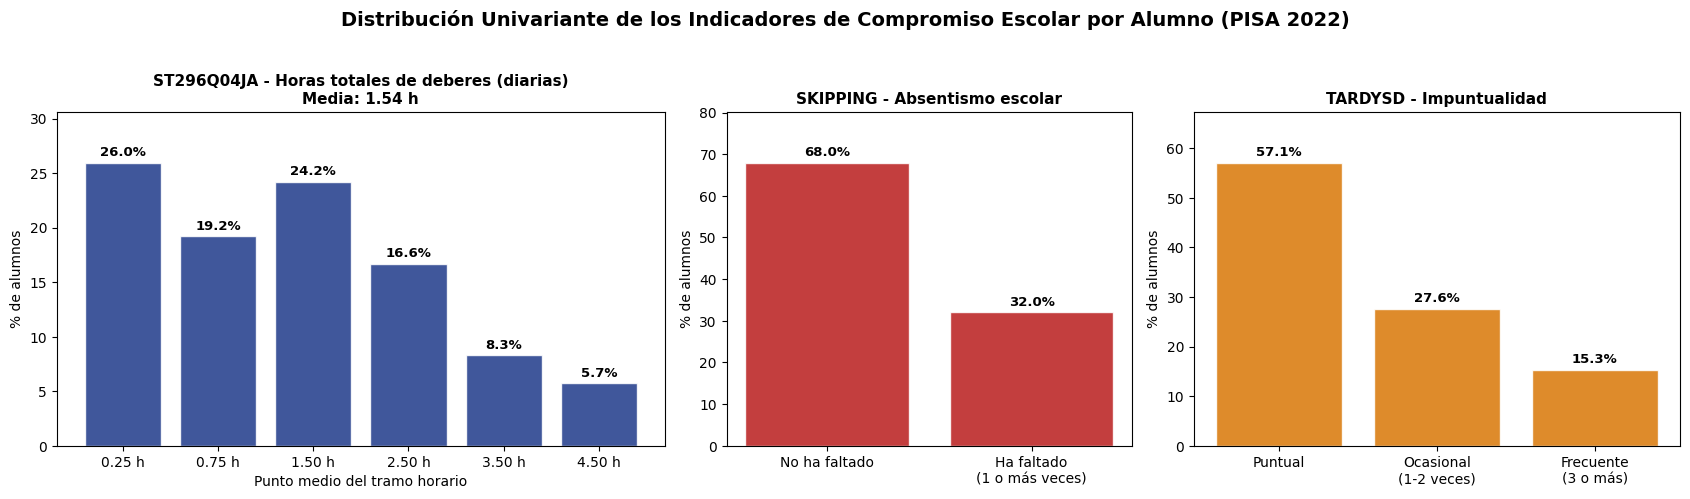

In [100]:
# Función reutilizable: barras con el porcentaje de alumnos en cada categoría de un índice
def graficar_barras_categoria(ax, serie, etiquetas, color, titulo):
    """Dibuja el porcentaje muestral de cada categoría con su valor anotado encima."""
    porcentajes = serie.dropna().value_counts(normalize=True).sort_index() * 100
    nombres = [etiquetas[int(v)] for v in porcentajes.index]

    barras = ax.bar(nombres, porcentajes.values, color=color, edgecolor='white', alpha=0.85)
    ax.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=9.5, fontweight='bold')

    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_ylabel('% de alumnos')
    ax.set_ylim(0, porcentajes.max() * 1.18)


# Distribución univariante de las 3 variables del índice en PISA 2022
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.5, 1, 1.2]})

# Panel 1: tramos de horas totales de deberes (variable discreta en 6 valores)
porcentajes_deberes = (
    df_analisis_esfuerzo_2022_lvl_alumno['ST296Q04JA']
    .value_counts(normalize=True)
    .sort_index() * 100
)
barras_deberes = axes[0].bar(
    [f'{h:.2f} h' for h in porcentajes_deberes.index], porcentajes_deberes.values,
    color='#1e3a8a', edgecolor='white', alpha=0.85
)
axes[0].bar_label(barras_deberes, fmt='%.1f%%', padding=3, fontsize=9.5, fontweight='bold')
media_deberes_2022 = df_analisis_esfuerzo_2022_lvl_alumno['ST296Q04JA'].mean()
axes[0].set_title(
    f'ST296Q04JA - Horas totales de deberes (diarias)\nMedia: {media_deberes_2022:.2f} h',
    fontsize=11, fontweight='bold'
)
axes[0].set_xlabel('Punto medio del tramo horario')
axes[0].set_ylabel('% de alumnos')
axes[0].set_ylim(0, porcentajes_deberes.max() * 1.18)

# Paneles 2 y 3: índices de asistencia
graficar_barras_categoria(
    axes[1], df_analisis_esfuerzo_2022_lvl_alumno['SKIPPING'],
    etiquetas_skipping, '#b91c1c', 'SKIPPING - Absentismo escolar'
)
graficar_barras_categoria(
    axes[2], df_analisis_esfuerzo_2022_lvl_alumno['TARDYSD'],
    etiquetas_tardysd, '#d97706', 'TARDYSD - Impuntualidad'
)

plt.suptitle(
    'Distribución Univariante de los Indicadores de Compromiso Escolar por Alumno (PISA 2022)',
    fontsize=14, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.show()

**Hallazgos del análisis univariante:**
* **Asimetría positiva en el tiempo de deberes (`ST296Q04JA`):** la mayor parte del alumnado se concentra en los tramos bajos (el $26,0\%$ declara $0,25$ h diarias y el $69,4\%$ no supera $1,50$ h), con una media de $1,54$ h y una cola derecha de sobrecarga (un $14,0\%$ dedica $3,5$ h o más).
* **Absentismo (`SKIPPING`):** un $32,0\%$ de los alumnos ($29,5\%$ ponderado por `SENWT`) ha faltado al menos una vez a un día entero o a clases sueltas en las dos últimas semanas.
* **Impuntualidad (`TARDYSD`):** es el comportamiento de desapego más extendido: el $42,9\%$ de los alumnos ha llegado tarde al menos una vez ($27,6\%$ de forma ocasional y $15,3\%$ de forma frecuente).
* **Cobertura:** las dos variables de asistencia tienen menos nulos ($3,9\%$ y $4,2\%$) que el tiempo de deberes ($8,4\%$), por lo que en 2022 la variable que más reduce la muestra completa es la de deberes.

## 2.2 Curvas de saturación y la paradoja de los estratos (Nivel Alumno vs. Nivel Colegio)

Contrastamos la relación entre el tiempo de deberes y el rendimiento en Matemáticas descomponiendo dos niveles de análisis: el **alumno individual** (donde `ST296Q04JA` toma 6 valores discretos en funcion de las horas de debres) frente al **colegio (`CNTSCHID`)** (donde la carga media del centro `Deberes_Medios_Colegio` actúa como una variable continua).

* **Agrupación en 6 perfiles de `Titularidad | Ubicación` (`TIPO_UBI`):** Para garantizar un tamaño muestral robusto en las curvas continuas por centro y preservar la legibilidad visual, reducimos los 18 estratos fijos en los **6 bloques estructurales de `Titularidad | Ubicación`** (`Privado | Urbano`, `Privado | Rural`, `Concertado | Urbano`, `Concertado | Rural`, `Público | Urbano` y `Público | Rural`), omitiendo la subdivisión por tamaño del centro.

* **Construcción de la tabla intercuartílica previa (`Q1` a `Q4`):** Antes de graficar las curvas continuas, clasificamos a los colegios dentro de cada país y titularidad (`groupby(['CNT', 'TIPO'])`) en **4 cuartiles de exigencia horaria de deberes** —desde `Q1 (Baja carga: 25% de colegios con menor media de deberes)` hasta `Q4 (Alta exigencia: 25% de colegios con mayor media de deberes)`— con el objetivo de cuantificar en puntos PISA el diferencial neto de rendimiento (`Diferencia Q4 - Q1`) entre escuelas de baja y alta exigencia.


Rendimiento medio del colegio por agrupacion TIPO | UBI y au nota de matemáticas asociada:


Cuartil_Exigencia_Colegio,TIPO_UBI,Q1 (Baja carga),Q2 (Carga media-baja),Q3 (Carga media-alta),Q4 (Alta exigencia),Diferencia (Q4 - Q1)
0,Concertado | Rural,461.37,483.12,480.89,512.06,50.69
1,Concertado | Urbano,470.81,479.70,490.13,497.11,26.30
2,Privado | Rural,485.25,518.74,522.17,498.17,12.92
3,Privado | Urbano,492.05,508.35,525.98,527.05,35.00
4,Público | Rural,454.00,463.32,469.34,466.69,12.69
5,Público | Urbano,449.49,469.76,484.60,495.86,46.37


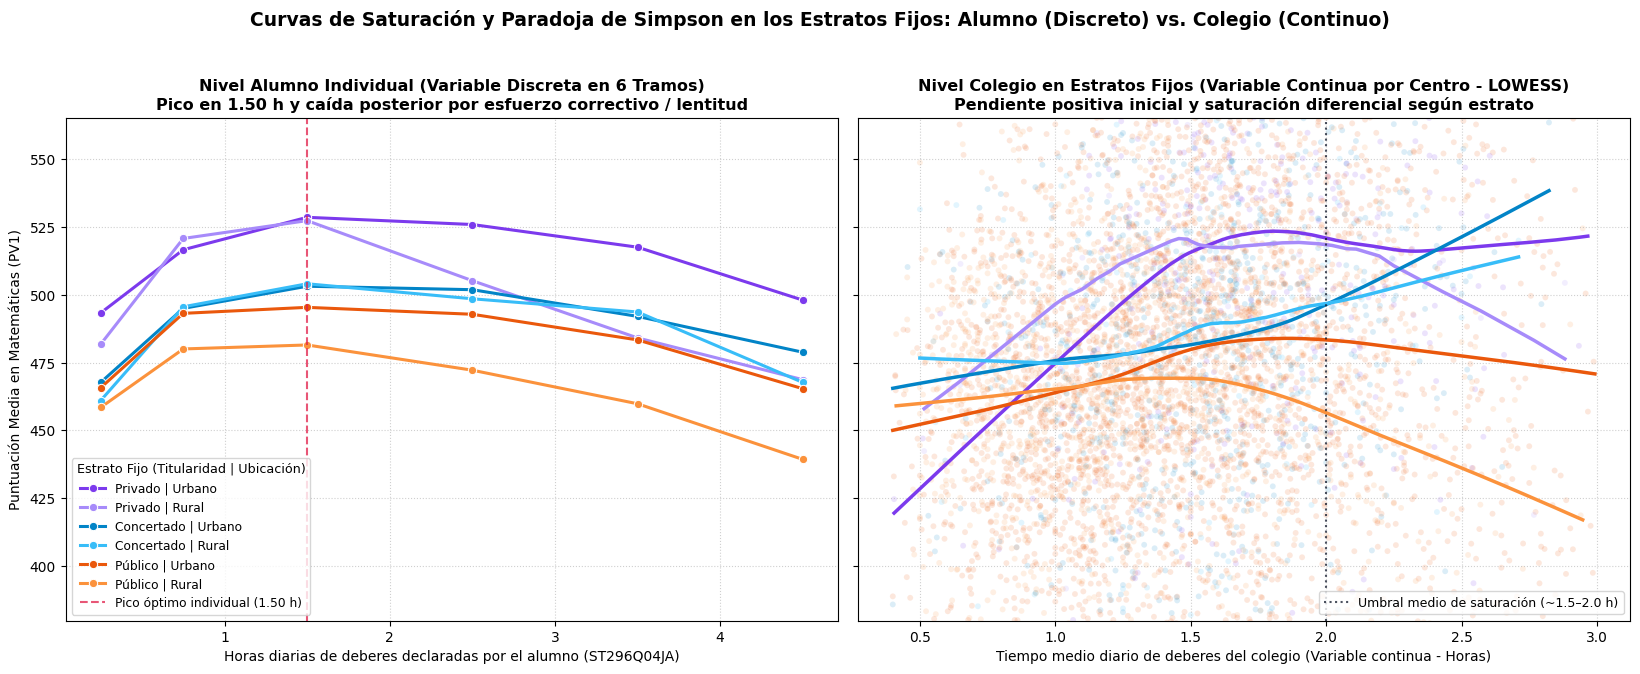

In [101]:
# Consolidación del descriptor de estrato fijo en los 6 perfiles de Titularidad | Ubicación (TIPO_UBI)
df_analisis_esfuerzo_2022_lvl_alumno['TIPO'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[0]
df_analisis_esfuerzo_2022_lvl_alumno['UBI'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[1]
df_analisis_esfuerzo_2022_lvl_alumno['TAM'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[2]
df_analisis_esfuerzo_2022_lvl_alumno['TIPO_UBI'] = (
    df_analisis_esfuerzo_2022_lvl_alumno['TIPO'] + ' | ' + df_analisis_esfuerzo_2022_lvl_alumno['UBI']
)

# Agregación a nivel de colegio (centros con al menos 10 alumnos evaluados y rango representativo 0.4–3.0 h)
df_colegios_2022 = (
    df_analisis_esfuerzo_2022_lvl_alumno.groupby(
        ['CNT', 'CNTSCHID', 'PERFIL_CODE', 'PERFIL_DESC', 'TIPO', 'UBI', 'TIPO_UBI'], observed=True
    )
    .agg(
        N_Alumnos=('CNTSTUID', 'count'),
        Deberes_Medios_Colegio=('ST296Q04JA', 'mean'),
        PV1MATH_Media_Colegio=(col_pv_math, 'mean'),
    )
    .reset_index()
)
df_colegios_2022 = df_colegios_2022[
    (df_colegios_2022['N_Alumnos'] >= 10) & (df_colegios_2022['Deberes_Medios_Colegio'].between(0.4, 3.0))
].copy()

# División de los colegios en 4 cuartiles de exigencia de deberes dentro de cada País y Titularidad
df_colegios_2022['Cuartil_Exigencia_Colegio'] = (
    df_colegios_2022.groupby(['CNT', 'TIPO'], observed=True)['Deberes_Medios_Colegio']
    .transform(
        lambda x: pd.qcut(
            x, 4,
            labels=['Q1 (Baja carga)', 'Q2 (Carga media-baja)', 'Q3 (Carga media-alta)', 'Q4 (Alta exigencia)'],
            duplicates='drop'
        ) if len(x) >= 4 else np.nan
    )
)

# Tabla comparativa intercuartílica del rendimiento medio del colegio (Q1 a Q4) por agrupación TIPO | UBI
tabla_simpson_colegios = (
    df_colegios_2022.dropna(subset=['Cuartil_Exigencia_Colegio'])
    .groupby(['TIPO_UBI', 'Cuartil_Exigencia_Colegio'], observed=True)['PV1MATH_Media_Colegio']
    .mean()
    .unstack()
    .round(2)
)
tabla_simpson_colegios['Diferencia (Q4 - Q1)'] = (
    tabla_simpson_colegios['Q4 (Alta exigencia)'] - tabla_simpson_colegios['Q1 (Baja carga)']
).round(2)
print('\nRendimiento medio del colegio por agrupacion TIPO | UBI y au nota de matemáticas asociada:')
display(tabla_simpson_colegios.reset_index())

orden_tipo_ubi = [
    'Privado | Urbano', 'Privado | Rural',
    'Concertado | Urbano', 'Concertado | Rural',
    'Público | Urbano', 'Público | Rural'
]
paleta_tipo_ubi = {
    'Privado | Urbano': '#7c3aed', 'Privado | Rural': '#a78bfa',
    'Concertado | Urbano': '#0284c7', 'Concertado | Rural': '#38bdf8',
    'Público | Urbano': '#ea580c', 'Público | Rural': '#fb923c'
}

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5), sharey=True)

# Panel izquierdo: Nivel Alumno Individual (Variable discreta en 6 tramos)
sns.lineplot(
    data=df_analisis_esfuerzo_2022_lvl_alumno,
    x='ST296Q04JA', y=col_pv_math,
    hue='TIPO_UBI', hue_order=orden_tipo_ubi, palette=paleta_tipo_ubi,
    marker='o', linewidth=2.2, errorbar=None, ax=axes[0]
)
axes[0].axvline(1.50, color='#e11d48', linestyle='--', alpha=0.75, label='Pico óptimo individual (1.50 h)')
axes[0].set_title(
    'Nivel Alumno Individual (Variable Discreta en 6 Tramos)\nPico en 1.50 h y caída posterior por esfuerzo correctivo / lentitud',
    fontsize=11.5, fontweight='bold'
)
axes[0].set_xlabel('Horas diarias de deberes declaradas por el alumno (ST296Q04JA)')
axes[0].set_ylabel('Puntuación Media en Matemáticas (PV1)')
axes[0].legend(title='Estrato Fijo (Titularidad | Ubicación)', fontsize=8.8, title_fontsize=9.2, loc='lower left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel derecho: Nivel Colegio en Estratos Fijos (Variable Continua: Media del Colegio con suavizado LOWESS)
sns.scatterplot(
    data=df_colegios_2022,
    x='Deberes_Medios_Colegio', y='PV1MATH_Media_Colegio',
    hue='TIPO_UBI', hue_order=orden_tipo_ubi, palette=paleta_tipo_ubi,
    alpha=0.14, s=18, legend=False, ax=axes[1]
)
for grupo in orden_tipo_ubi:
    sub_col = df_colegios_2022[df_colegios_2022['TIPO_UBI'] == grupo]
    sns.regplot(
        data=sub_col,
        x='Deberes_Medios_Colegio', y='PV1MATH_Media_Colegio',
        lowess=True, scatter=False, ci=None,
        color=paleta_tipo_ubi[grupo],
        line_kws={'linewidth': 2.5},
        ax=axes[1]
    )

axes[1].axvline(2.0, color='#0f172a', linestyle=':', alpha=0.75, label='Umbral medio de saturación (~1.5–2.0 h)')
axes[1].set_title(
    'Nivel Colegio en Estratos Fijos (Variable Continua por Centro - LOWESS)\nPendiente positiva inicial y saturación diferencial según estrato',
    fontsize=11.5, fontweight='bold'
)
axes[1].set_xlabel('Tiempo medio diario de deberes del colegio (Variable continua - Horas)')
axes[1].set_ylabel('Nota Media del Colegio en Matemáticas (PV1)')
axes[1].set_ylim(380, 565)
axes[1].legend(loc='lower right', fontsize=9, frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle(
    'Curvas de Saturación y Paradoja de Simpson en los Estratos Fijos: Alumno (Discreto) vs. Colegio (Continuo)',
    fontsize=13.5, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.show()

**Hallazgos sobre las curvas de saturación y la Paradoja de Simpson en los estratos fijos:**

* **Pico óptimo en $1,50h$ y caída posterior a nivel de alumno individual (Panel izquierdo):** Al evaluar al estudiante de forma individual  las curvas ascienden desde $0,25h$ hasta alcanzar su **máximo rendimiento global en torno a $1,50h$ diarias** . A partir de ese umbral, la pendiente se vuelve negativa hacia los tramos de $2,50  \text{ a } 4,50h$ porque, dentro de una misma clase, quien invierte tres o cuatro horas en completar la tarea suele ser el alumno con menor fluidez o mayores dificultades de aprendizaje (*causalidad inversa*).

* **Salto intercuartílico positivo a nivel de colegio en la tabla comparativa (`Q4 vs. Q1`):** Como recoge la tabla comparativa previa al gráfico, al agregar por centro (`CNTSCHID`) y comparar dentro de cada ubicacion y titularidad el cuartil de mayor exigencia horaria (`Q4`) frente al de menor carga (`Q1`), se neutraliza la lentitud individual del alumno y aparece una diferencia positiva en los 6 perfiles.


* **Tendencia continua y umbral de saturación diferencial por estrato (Panel derecho):** Las curvas sobre el tiempo medio continuo del colegio confirman una pendiente inicial positiva en todos los estratos, pero revelan que el umbral de rendimientos decrecientes depende del entorno del centro: en `Público | Rural` la curva toca techo pronto (en torno a **$1,25–1,50 h$**) y desciende en centros con sobrecarga horaria; en `Privado` y `Público | Urbano` el ascenso se sostiene hasta estabilizarse alrededor de las **$1,80–2,00h$**; mientras que en los centros `Concertados` (urbanos y rurales) la pendiente positiva se prolonga de forma más sostenida en los tramos altos de exigencia.

### ¿Qué concluimos sobre el tiempo de deberes?

Como evidencia el análisis agregado por centro escolar y estrato, el impacto del tiempo dedicado a los deberes sobre el rendimiento en matemáticas está fuertemente condicionado por la titularidad y ubicación del entorno. Es decir, el entorno económico-social.

 Las curvas de saturación demuestran que, si bien una carga moderada de tareas tiene una pendiente positiva inicial, los perfiles con mayor respaldo estructural logran sostener esta mejora durante más tiempo, mientras que los entornos vulnerables (como el público rural) tocan techo y decaen más rápido. Esta disparidad confirma visualmente la premisa central de este TFM:
 
 **El rendimiento es multifactorial y resulta estadísticamente inviable medir el impacto sobre la nota únicamente con el tiempo dedicado a deberes sin un modelo predictivo que contemple otras variables externas, como el estatus socioeconómico o los recursos**

## 2.3 Comparativa visual dual por estratos fijos: deberes y asistencia (PISA 2022)

Comparamos los 6 grupos de estratos fijos de `Titularidad | Ubicación` (los mismos del apartado 2.2) en las dos dimensiones del compromiso escolar:

* **Panel izquierdo:** horas medias diarias de deberes (`ST296Q04JA`) por estrato fijo.
* **Panel derecho:** tasas emparejadas de **absentismo** (% de alumnos con `SKIPPING = 1`) e **impuntualidad** (% de alumnos con `TARDYSD ≥ 1`) por estrato fijo, señalando además qué parte de la impuntualidad es frecuente (`TARDYSD = 2`).

💡 **Por qué expresamos la asistencia como tasas y ponderamos por `SENWT`**

* `SKIPPING` y `TARDYSD` son categóricos, por lo que su media aritmética no tiene una lectura directa. Convertidos en el **porcentaje de alumnos que han faltado o llegado tarde al menos una vez**, ambos se miden en la misma escala (0–100 %) y pueden compararse en barras emparejadas.
* El peso de senado (`SENWT`) da el mismo peso total a cada país, evitando que los sistemas con más alumnos evaluados dominen el perfil de cada estrato.

In [102]:
# Media ponderada que ignora a los alumnos sin dato en la columna o en el peso
def media_ponderada(datos, columna, peso='SENWT'):
    validos = datos[[columna, peso]].dropna()
    return np.average(validos[columna], weights=validos[peso])


# Número con coma decimal para las anotaciones de los gráficos
def formato_es(valor, decimales):
    return f'{valor:.{decimales}f}'.replace('.', ',')


# Indicadores binarios de asistencia expresados en porcentaje (NaN si el alumno no respondió)
tardysd_2022 = df_analisis_esfuerzo_2022_lvl_alumno['TARDYSD']

df_asistencia_2022 = df_analisis_esfuerzo_2022_lvl_alumno.assign(
    Pct_Absentismo=df_analisis_esfuerzo_2022_lvl_alumno['SKIPPING'] * 100,
    Pct_Impuntualidad=np.where(tardysd_2022.isna(), np.nan, (tardysd_2022 >= 1) * 100.0),
    Pct_Impuntualidad_Frecuente=np.where(tardysd_2022.isna(), np.nan, (tardysd_2022 == 2) * 100.0),
)

# Tabla resumen por grupo de Titularidad | Ubicación
filas_estratos = []
for grupo, datos_grupo in df_asistencia_2022.groupby('TIPO_UBI'):
    filas_estratos.append({
        'TIPO_UBI': grupo,
        'Alumnos': len(datos_grupo),
        'Horas_Deberes': media_ponderada(datos_grupo, 'ST296Q04JA'),
        'Pct_Absentismo': media_ponderada(datos_grupo, 'Pct_Absentismo'),
        'Pct_Impuntualidad': media_ponderada(datos_grupo, 'Pct_Impuntualidad'),
        'Pct_Impuntualidad_Frecuente': media_ponderada(datos_grupo, 'Pct_Impuntualidad_Frecuente'),
    })

tabla_estratos_2022 = pd.DataFrame(filas_estratos).set_index('TIPO_UBI').loc[orden_tipo_ubi]

# Referencias globales ponderadas de toda la muestra 2022
media_global_deberes = media_ponderada(df_asistencia_2022, 'ST296Q04JA')
media_global_absentismo = media_ponderada(df_asistencia_2022, 'Pct_Absentismo')
media_global_impuntualidad = media_ponderada(df_asistencia_2022, 'Pct_Impuntualidad')

print('Indicadores de compromiso por estrato fijo (Titularidad | Ubicación) en PISA 2022, ponderados por SENWT:')
display(tabla_estratos_2022)

Indicadores de compromiso por estrato fijo (Titularidad | Ubicación) en PISA 2022, ponderados por SENWT:


,Alumnos,Horas_Deberes,Pct_Absentismo,Pct_Impuntualidad,Pct_Impuntualidad_Frecuente
TIPO_UBI,,,,,
Privado | Urbano,10938,1.77,24.43,37.17,12.50
Privado | Rural,938,1.48,26.13,46.29,16.04
Concertado | Urbano,23740,1.55,23.88,44.70,17.22
Concertado | Rural,4691,1.41,25.41,39.94,12.93
Público | Urbano,105814,1.57,31.17,44.56,15.97
Público | Rural,39973,1.32,29.66,41.76,14.45


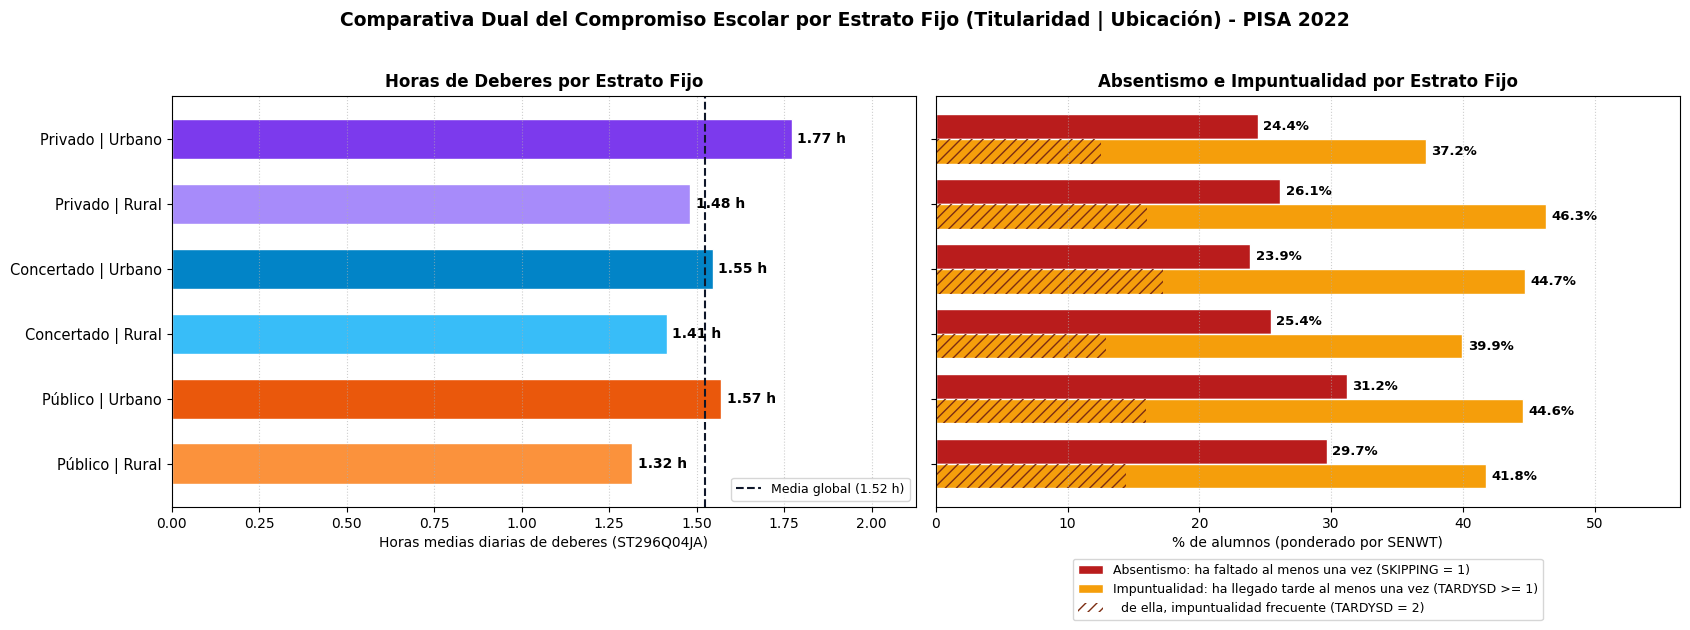

In [103]:
# Gráfico dual: horas de deberes (izquierda) y tasas emparejadas de absentismo e impuntualidad (derecha)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), sharey=True)
posiciones = np.arange(len(orden_tipo_ubi))

# --- Panel izquierdo: horas medias diarias de deberes por estrato fijo ---
barras_horas = axes[0].barh(
    posiciones,
    tabla_estratos_2022['Horas_Deberes'],
    color=[paleta_tipo_ubi[g] for g in orden_tipo_ubi],
    edgecolor='white', height=0.62,
)
axes[0].bar_label(barras_horas, fmt='%.2f h', padding=4, fontsize=10, fontweight='bold')
axes[0].axvline(
    media_global_deberes, color='#0f172a', linestyle='--', linewidth=1.5,
    label=f'Media global ({media_global_deberes:.2f} h)'
)

axes[0].set_yticks(posiciones)
axes[0].set_yticklabels(orden_tipo_ubi, fontsize=10.5)
axes[0].invert_yaxis()
axes[0].set_xlim(0, tabla_estratos_2022['Horas_Deberes'].max() * 1.2)
axes[0].set_xlabel('Horas medias diarias de deberes (ST296Q04JA)')
axes[0].set_title('Horas de Deberes por Estrato Fijo', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, axis='x', linestyle=':', alpha=0.6)

# --- Panel derecho: barras emparejadas de absentismo e impuntualidad por estrato fijo ---
alto_barra = 0.38

barras_abs = axes[1].barh(
    posiciones - alto_barra / 2, tabla_estratos_2022['Pct_Absentismo'],
    height=alto_barra, color='#b91c1c', edgecolor='white',
    label='Absentismo: ha faltado al menos una vez (SKIPPING = 1)'
)
barras_imp = axes[1].barh(
    posiciones + alto_barra / 2, tabla_estratos_2022['Pct_Impuntualidad'],
    height=alto_barra, color='#f59e0b', edgecolor='white',
    label='Impuntualidad: ha llegado tarde al menos una vez (TARDYSD >= 1)'
)

# Parte frecuente de la impuntualidad (TARDYSD = 2) superpuesta con trama
axes[1].barh(
    posiciones + alto_barra / 2, tabla_estratos_2022['Pct_Impuntualidad_Frecuente'],
    height=alto_barra, color='none', edgecolor='#7c2d12', hatch='///', linewidth=0,
    label='  de ella, impuntualidad frecuente (TARDYSD = 2)'
)

axes[1].bar_label(barras_abs, fmt='%.1f%%', padding=4, fontsize=9.5, fontweight='bold')
axes[1].bar_label(barras_imp, fmt='%.1f%%', padding=4, fontsize=9.5, fontweight='bold')

axes[1].set_xlim(0, tabla_estratos_2022[['Pct_Absentismo', 'Pct_Impuntualidad']].max().max() * 1.22)
axes[1].set_xlabel('% de alumnos (ponderado por SENWT)')
axes[1].set_title('Absentismo e Impuntualidad por Estrato Fijo', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), fontsize=9, frameon=True)
axes[1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.suptitle(
    'Comparativa Dual del Compromiso Escolar por Estrato Fijo (Titularidad | Ubicación) - PISA 2022',
    fontsize=13.5, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

**Hallazgos de la comparativa dual por estratos fijos:**
* **Deberes:** los centros `Privado | Urbano` son los que más horas exigen ($1,77$ h diarias), frente a $1,32$ h en `Público | Rural`. En las tres titularidades, el entorno urbano dedica más tiempo a los deberes que el rural (privado $1,77$ vs. $1,48$ h; concertado $1,55$ vs. $1,41$ h; público $1,57$ vs. $1,32$ h).
* **Absentismo:** la titularidad marca la diferencia: los centros públicos concentran las tasas más altas ($31,2\%$ urbano y $29,7\%$ rural), frente a un $23,9$–$26,1\%$ en los centros privados y concertados.
* **Impuntualidad:** el patrón no sigue la titularidad: `Privado | Urbano` es el estrato más puntual ($37,2\%$ ha llegado tarde alguna vez y $12,5\%$ con frecuencia), mientras que `Privado | Rural` ($46,3\%$), `Concertado | Urbano` ($44,7\%$) y `Público | Urbano` ($44,6\%$) presentan las tasas más altas. El grupo `Privado | Rural` tiene pocos alumnos ($938$), por lo que su estimación es menos estable.
* **Lectura conjunta:** `Privado | Urbano` combina más horas de deberes con menos absentismo e impuntualidad, mientras que `Público | Urbano` combina una carga de deberes cercana a la media con la mayor tasa de absentismo. El compromiso escolar no es una única dimensión: un estrato puede exigir muchas horas de deberes y aun así tener problemas de asistencia.

# 3. Comprobación de Disponibilidad Longitudinal y Crosswalk (2012–2022)

## 3.1 Tabla de equivalencias metodológicas (Crosswalk 2012–2022)

Para construir las 3 variables del índice de compromiso y competencia de forma consistente a lo largo de la década, aplicamos el siguiente **Crosswalk exacto** al **Tiempo de deberes**, al **Absentismo** y a la **Impuntualidad**:

| Edición PISA | Variable `tiempo_deberes_totales_diarios` | Variable `SKIPPING` | Variable `TARDYSD` | Regla de Armonización |
| :--- | :--- | :--- | :--- | :--- |
| **PISA 2022** | `ST296Q04JA` | **`SKIPPING`** (oficial OCDE) | **`TARDYSD`** (oficial OCDE) | Tiempo de deberes: mapeo de tramos ordinales (1–6) a puntos medios $[0.25, 4.50]$ h. Asistencia: índices publicados por la OCDE (validados en la Sección 1.5.1). |
| **PISA 2018** | `EC159Q01HA` + `EC159Q02HA` | `ST062Q01TA` + `ST062Q02TA` | `ST062Q03TA` | Tiempo de deberes: conversión de categorías desplazadas de horas y minutos tras el colegio acotada a $[0.0, 4.50]$ h (cuestionario opcional *Educational Career*). Asistencia: construida con la regla oficial. |
| **PISA 2015** | `ST071Q01NA` a `ST071Q03NA` | `ST062Q01TA` + `ST062Q02TA` | `ST062Q03TA` | Tiempo de deberes: suma semanal de las 3 materias troncales dividida entre $5$ días lectivos y acotada a $[0.0, 4.50]$ h. Asistencia: construida con la regla oficial. |
| **PISA 2012** | `ST57Q01`, `ST57Q02`, `ST57Q05` | `ST09Q01` + `ST115Q01` | `ST08Q01` | Tiempo de deberes: suma semanal de modalidades de deberes en casa dividida entre $5$ días lectivos, acotada a $[0.0, 4.50]$ h. Asistencia: construida con la regla oficial. |

# 4. Procesamiento de Ediciones y Cruce con Estratos Fijos (2022, 2012, 2015 y 2018)

## 4.1 Esquema estándar y preparación de la edición 2022

Definimos la estructura común de columnas para todas las ediciones (incluyendo el identificador único del alumno, su estrato fijo escolar `PERFIL_CODE` / `PERFIL_DESC`, los pesos muestrales y las 3 variables del índice de compromiso y competencia) y consolidamos la tabla base de **PISA 2022**.

In [104]:
# Estructura estándar de columnas por alumno, común a las cuatro ediciones
columnas_estandar_alumno = [
    'CNT', 'CNTSCHID', 'CNTSTUID', 'year',
    'PERFIL_CODE', 'PERFIL_DESC',
    'W_FSTUWT', 'SENWT',
    'tiempo_deberes_totales_diarios',
    'SKIPPING',
    'TARDYSD',
]

In [105]:
# Comprobación visual de las 3 variables del índice en una edición
def graficar_indicadores_edicion(df_edicion, year):
    """Histograma de horas de deberes y distribución porcentual de SKIPPING y TARDYSD."""
    serie_deberes = df_edicion['tiempo_deberes_totales_diarios'].dropna()

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.5, 1, 1.2]})

    # Panel 1: histograma del tiempo diario de deberes con su media y mediana
    sns.histplot(
        serie_deberes, kde=False, bins=30,
        color='#2563eb', edgecolor='white', alpha=0.65, ax=axes[0]
    )
    axes[0].axvline(serie_deberes.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_deberes.mean():.2f} h')
    axes[0].axvline(serie_deberes.median(), color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {serie_deberes.median():.2f} h')
    axes[0].set_title(f'Distribución de Horas Diarias de Deberes (PISA {year})', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
    axes[0].set_ylabel('Frecuencia (Alumnos)')
    axes[0].legend()

    # Paneles 2 y 3: porcentaje de alumnos en cada categoría de asistencia
    graficar_barras_categoria(
        axes[1], df_edicion['SKIPPING'], etiquetas_skipping,
        '#b91c1c', f'Absentismo - SKIPPING (PISA {year})'
    )
    graficar_barras_categoria(
        axes[2], df_edicion['TARDYSD'], etiquetas_tardysd,
        '#d97706', f'Impuntualidad - TARDYSD (PISA {year})'
    )

    plt.suptitle(f'Distribución de las 3 Variables del Índice de Compromiso y Competencia - Edición {year}', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

In [106]:
# Estandarización de nombres para la tabla de alumnos con estrato fijo de PISA 2022
df_base_2022_alumno = df_analisis_esfuerzo_2022_lvl_alumno.rename(columns={
    'ST296Q04JA': 'tiempo_deberes_totales_diarios',
})[columnas_estandar_alumno].copy()

display(df_base_2022_alumno.head())
display(df_base_2022_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,SKIPPING,TARDYSD
0,AUS,3600477,3600001,2022,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,21.49,0.41,0.75,0.00,0.00
1,AUS,3600016,3600002,2022,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,26.35,0.50,3.50,1.00,0.00
2,AUS,3600669,3600004,2022,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,34.43,0.65,3.50,1.00,1.00
3,AUS,3600495,3600006,2022,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,30.61,0.58,NaN,NaN,NaN
4,AUS,3600325,3600008,2022,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,8.86,0.17,0.25,1.00,1.00


(186094, 11)

## 4.2 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2012

### 4.2.1 Construcción del equivalente de Tiempo Total de Deberes, Absentismo (`SKIPPING`) e Impuntualidad (`TARDYSD`) en PISA 2012

En PISA 2012, el cuestionario dividía el tiempo de estudio semanal fuera de clase en varios ítems independientes. Para obtener una métrica armonizada y realista del tiempo total diario dedicado a los deberes (comparable con las ediciones posteriores), se agrupan las distintas modalidades de deberes y ayuda en el entorno familiar:

* **`ST57Q01`**: Trabajo autónomo / Deberes (*Homework*)
* **`ST57Q02`**: Deberes guiados o supervisados (*Guided Homework*)
* **`ST57Q05`**: Estudio o deberes con ayuda de los padres (*With Parent*)

**Regla de codificación:**
Se calcula la suma horizontal de las horas semanales reportadas en estas tres modalidades para capturar el volumen real de estudio en casa. Este total semanal se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$tiempo\_deberes\_totales\_diarios = \frac{ST57Q01 + ST57Q02 + ST57Q05}{5}$$

Para los **indicadores de asistencia**, PISA 2012 no publica `SKIPPING` ni `TARDYSD`, por lo que los construimos con la regla oficial de la Sección 1.3 a partir de los ítems equivalentes del Crosswalk: **`ST09Q01`** (faltar un día entero), **`ST115Q01`** (saltarse clases sueltas) y **`ST08Q01`** (llegar tarde). Después cruzamos con `pisa2012_estratos_fijos.parquet`.

In [107]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2012
ruta_est_2012 = RUTA_DATOS_ANUALES / 'pisa2012_estudiantes.parquet'
ruta_estratos_2012 = RUTA_ESTRATOS / 'pisa2012_estratos_fijos.parquet'

esquema_2012 = pq.read_schema(ruta_est_2012).names
columnas_tiempo_2012 = [c for c in ['ST57Q01', 'ST57Q02', 'ST57Q05'] if c in esquema_2012]

# Ítems de asistencia de 2012: día entero, clases sueltas y llegar tarde
items_asistencia_2012 = ['ST09Q01', 'ST115Q01', 'ST08Q01']

cols_est_2012 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + columnas_tiempo_2012 + items_asistencia_2012
))
df_est_2012 = pd.read_parquet(ruta_est_2012, columns=cols_est_2012)
df_estratos_2012 = pd.read_parquet(ruta_estratos_2012)

display(df_est_2012.head(2))

,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,ST57Q01,ST57Q02,ST57Q05,ST09Q01,ST115Q01,ST08Q01
0,AUS,00001,0000001,33.39,0.67,5.00,0.00,1.00,2.00,2.00,2.00
1,AUS,00002,0000001,33.39,0.67,5.00,0.00,0.00,1.00,1.00,1.00


In [108]:
# Cálculo del tiempo diario de deberes acotado a [0.0, 4.5] en 2012
df_est_2012['tiempo_deberes_totales_diarios'] = (
    df_est_2012[columnas_tiempo_2012].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

# Construcción de los índices de asistencia con la regla oficial de la OCDE
df_est_2012['SKIPPING'] = construir_skipping(df_est_2012['ST09Q01'], df_est_2012['ST115Q01'])
df_est_2012['TARDYSD'] = construir_tardysd(df_est_2012['ST08Q01'])

# Unión inner con los estratos fijos de PISA 2012
df_base_2012_alumno = df_est_2012.merge(
    df_estratos_2012,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)
df_base_2012_alumno['year'] = 2012
df_base_2012_alumno = df_base_2012_alumno[columnas_estandar_alumno].copy()

del df_est_2012, df_estratos_2012
gc.collect()

display(df_base_2012_alumno.head())
display(df_base_2012_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,SKIPPING,TARDYSD
0,AUS,0000001,00001,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.20,1.00,1.00
1,AUS,0000001,00002,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.00,0.00,0.00
2,AUS,0000001,00003,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,4.50,0.00,1.00
3,AUS,0000001,00004,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,1.80,0.00,1.00
4,AUS,0000001,00005,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,2.20,0.00,1.00


(265820, 11)

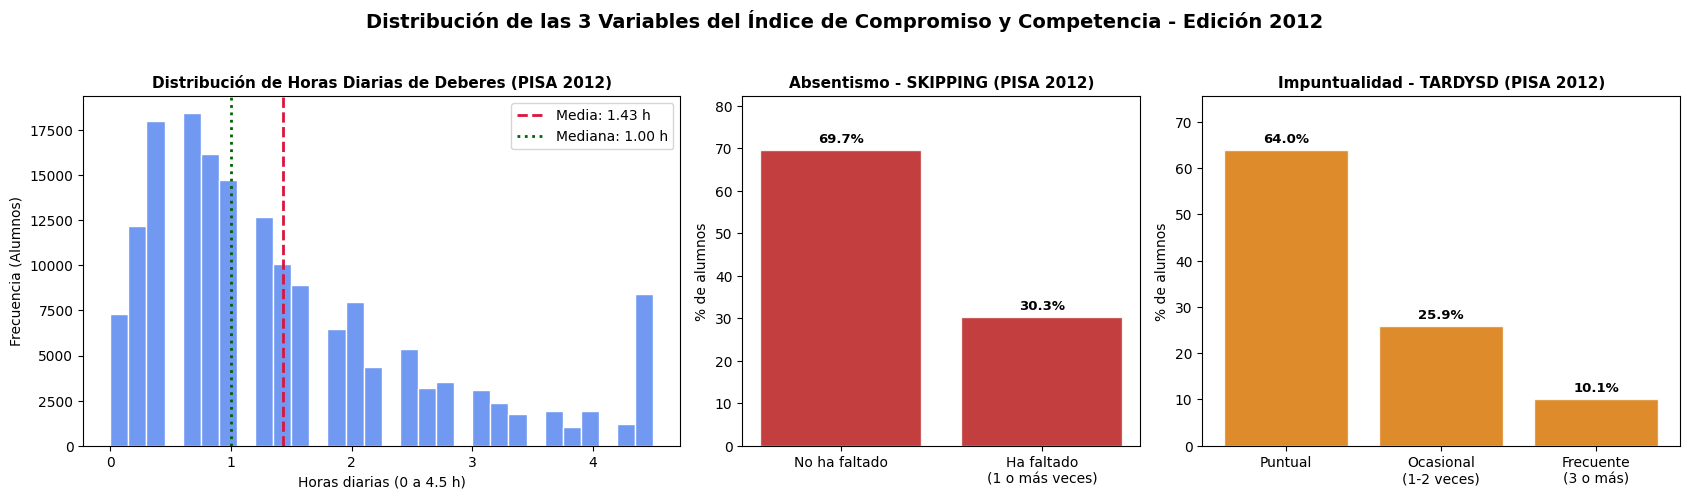

In [109]:
# Comprobación visual de las 3 variables extraídas en PISA 2012
graficar_indicadores_edicion(df_base_2012_alumno, 2012)

## 4.3 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2015

### 4.3.1 Construcción del equivalente de Tiempo Total de Deberes, Absentismo (`SKIPPING`) e Impuntualidad (`TARDYSD`) en PISA 2015

En PISA 2015 la OCDE no preguntó por el tiempo de estudio global en una sola variable, sino que desglosó las horas semanales dedicadas a los deberes por materias. Para obtener la métrica equivalente al tiempo total diario, aplicamos una transformación matemática agregando los ítems del cuestionario del estudiante:

* **`ST071Q01NA`**: Horas semanales en Ciencias
* **`ST071Q02NA`**: Horas semanales en Matemáticas
* **`ST071Q03NA`**: Horas semanales en Lectura/Lengua

**Regla de codificación:**
Se calcula la suma horizontal de las horas reportadas para obtener el volumen semanal total, y se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$\text{tiempo\_deberes\_totales\_diarios} = \frac{\sum_{i=1}^{3} \text{ST071Q0}i\text{NA}}{5}$$

Para los **indicadores de asistencia**, PISA 2015 tampoco publica `SKIPPING` ni `TARDYSD`, por lo que los construimos con la regla oficial de la Sección 1.3 a partir de **`ST062Q01TA`** (faltar un día entero), **`ST062Q02TA`** (saltarse clases sueltas) y **`ST062Q03TA`** (llegar tarde). Después cruzamos con `pisa2015_estratos_fijos.parquet`.

Comprobamos previamente qué se contempla en `OUTHOURS` contrastando la suma de las 5 materias frente a las 3 materias troncales. En **PISA 2022**, la propia OCDE acota el tiempo diario de deberes a un máximo de **4,5 horas/día**, mientras que en 2015 fijó un tope máximo (*top-coding*) de **70 horas semanales** para `OUTHOURS` en los microdatos.

In [110]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2015
ruta_est_2015 = RUTA_DATOS_ANUALES / 'pisa2015_estudiantes.parquet'
ruta_estratos_2015 = RUTA_ESTRATOS / 'pisa2015_estratos_fijos.parquet'

cols_5_materias = [f'ST071Q0{i}NA' for i in range(1, 6)]
cols_3_materias = ['ST071Q01NA', 'ST071Q02NA', 'ST071Q03NA']

# Ítems de asistencia comunes a 2015, 2018 y 2022: día entero, clases sueltas y llegar tarde
items_asistencia_st062 = ['ST062Q01TA', 'ST062Q02TA', 'ST062Q03TA']

cols_est_2015 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + cols_5_materias + ['OUTHOURS'] + items_asistencia_st062
))

df_est_2015 = pd.read_parquet(ruta_est_2015, columns=cols_est_2015)
df_estratos_2015 = pd.read_parquet(ruta_estratos_2015)

In [111]:
# Cálculo de las tres variantes de tiempo en 2015 para la validación metodológica frente a OUTHOURS
df_est_2015['outhours_oficial'] = (df_est_2015['OUTHOURS'] / 5).clip(lower=0.0, upper=4.5)

df_est_2015['manual_5_materias'] = (
    df_est_2015[cols_5_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

df_est_2015['manual_3_materias'] = (
    df_est_2015[cols_3_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

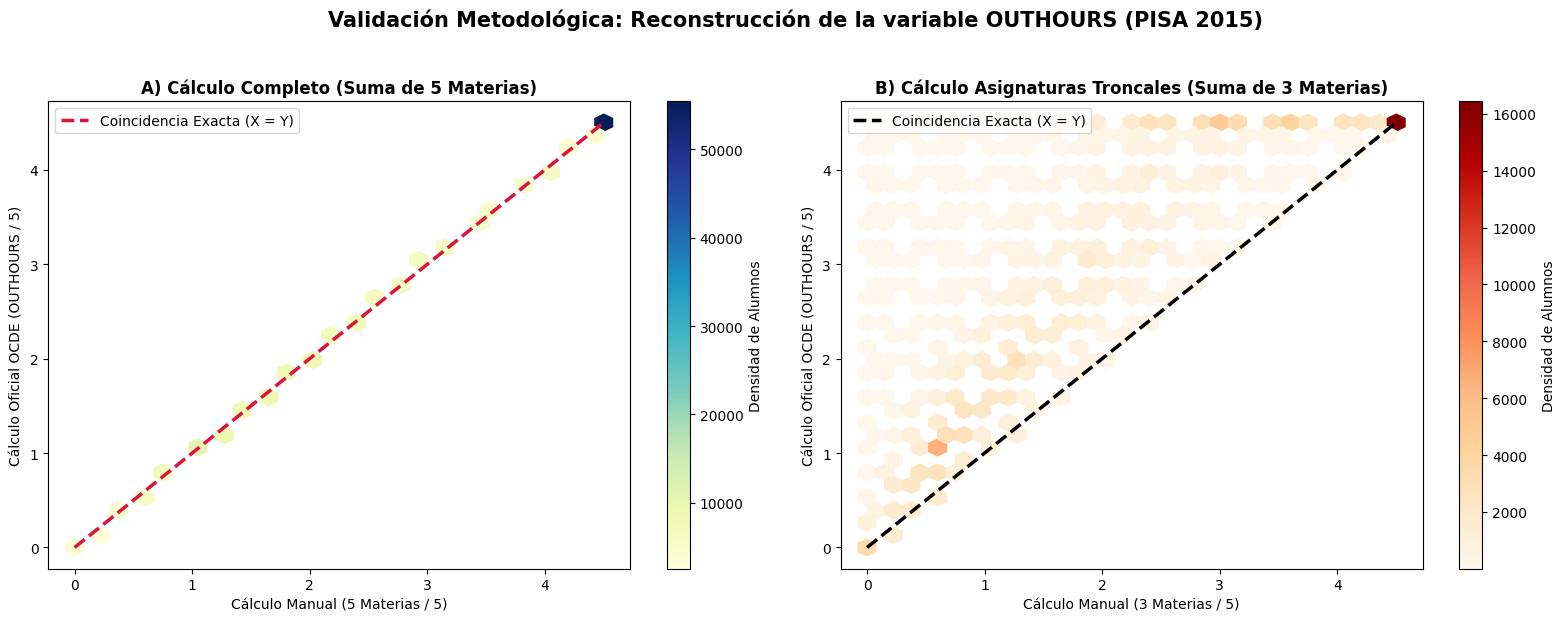

Correlación con 5 materias: 1.0000 (Ideal es 1.000)
Correlación con 3 materias: 0.8668


In [112]:
# Contraste visual Hexbin entre la reconstrucción con 5 materias y con las 3 materias troncales
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hb1 = axes[0].hexbin(
    x=df_est_2015['manual_5_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='YlGnBu', mincnt=1
)
axes[0].plot([0, 4.5], [0, 4.5], color='crimson', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb1 = fig.colorbar(hb1, ax=axes[0])
cb1.set_label('Densidad de Alumnos')
axes[0].set_title('A) Cálculo Completo (Suma de 5 Materias)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Cálculo Manual (5 Materias / 5)')
axes[0].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[0].legend()

hb2 = axes[1].hexbin(
    x=df_est_2015['manual_3_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='OrRd', mincnt=1
)
axes[1].plot([0, 4.5], [0, 4.5], color='black', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb2 = fig.colorbar(hb2, ax=axes[1])
cb2.set_label('Densidad de Alumnos')
axes[1].set_title('B) Cálculo Asignaturas Troncales (Suma de 3 Materias)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Cálculo Manual (3 Materias / 5)')
axes[1].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[1].legend()

plt.suptitle('Validación Metodológica: Reconstrucción de la variable OUTHOURS (PISA 2015)', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

corr_5 = df_est_2015['manual_5_materias'].corr(df_est_2015['outhours_oficial'])
corr_3 = df_est_2015['manual_3_materias'].corr(df_est_2015['outhours_oficial'])
print(f"Correlación con 5 materias: {corr_5:.4f} (Ideal es 1.000)")
print(f"Correlación con 3 materias: {corr_3:.4f}")

<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Criterio de Selección: Suma de 3 Materias Troncales frente a OUTHOURS (2015)
  </strong>
  Aunque la suma de las 5 materias reproduce exactamente <code>OUTHOURS</code> (r = 1,0000), dentro de ese índice se acumulan horas de otras actividades y asignaturas no evaluadas del mismo modo en otros cuestionarios PISA, lo que dispara artificialmente el número de horas de deberes en 2015 frente a las demás ediciones (2012, 2018 y 2022). Por lo tanto, para garantizar la comparabilidad inter-edición, nos quedamos con la suma de los tres ítems relativos a las asignaturas troncales de PISA (<code>manual_3_materias</code>).
</div>

In [113]:
# Asignación del tiempo de deberes (3 materias troncales) en 2015
df_est_2015['tiempo_deberes_totales_diarios'] = df_est_2015['manual_3_materias']

# Construcción de los índices de asistencia con la regla oficial de la OCDE
df_est_2015['SKIPPING'] = construir_skipping(df_est_2015['ST062Q01TA'], df_est_2015['ST062Q02TA'])
df_est_2015['TARDYSD'] = construir_tardysd(df_est_2015['ST062Q03TA'])

# Unión inner con los estratos fijos de PISA 2015
df_base_2015_alumno = df_est_2015.merge(
    df_estratos_2015,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)

df_base_2015_alumno['year'] = 2015
df_base_2015_alumno = df_base_2015_alumno[columnas_estandar_alumno].copy()

del df_est_2015, df_estratos_2015
gc.collect()

display(df_base_2015_alumno.head())
display(df_base_2015_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,SKIPPING,TARDYSD
0,AUS,3600001,3610676,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,0.80,0.00,1.00
1,AUS,3600001,3611874,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,0.80,1.00,1.00
2,AUS,3600001,3601769,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,NaN,1.00,1.00
3,AUS,3600001,3605996,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,3.40,0.00,0.00
4,AUS,3600001,3608147,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,33.45,0.65,0.60,1.00,0.00


(178022, 11)

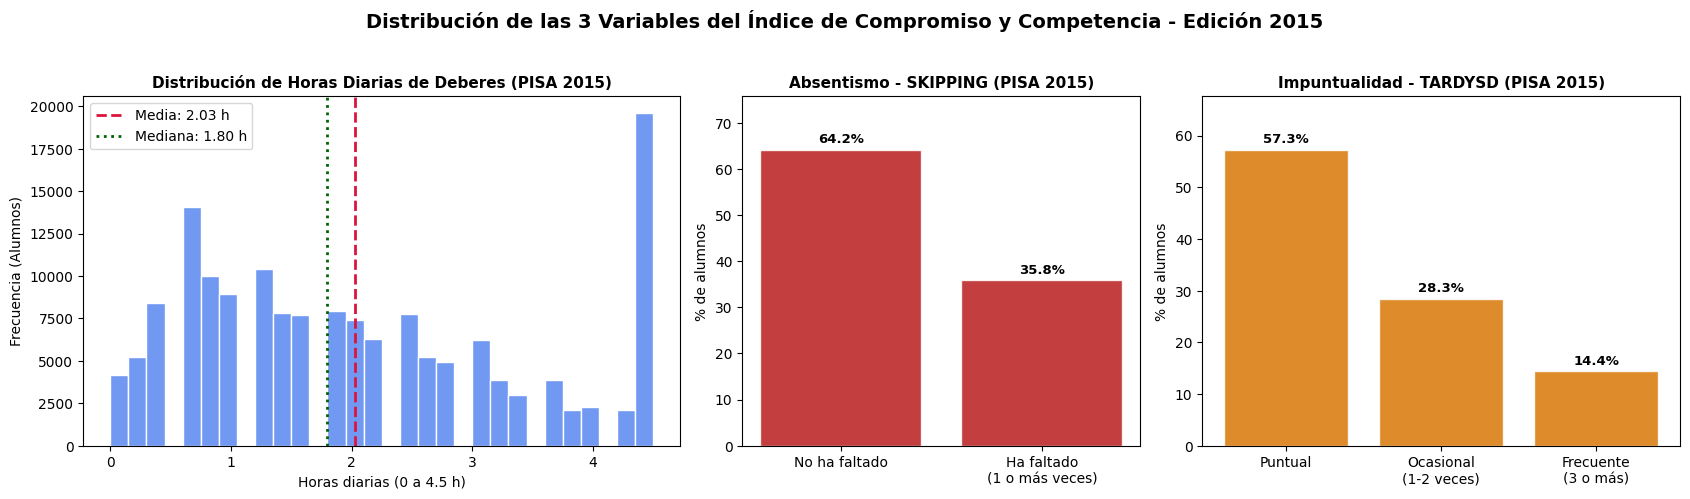

,tiempo_deberes_totales_diarios
count,159372.00
mean,2.03
std,1.37
min,0.00
25%,0.80
50%,1.80
75%,3.00
max,4.50


In [114]:
# Comprobación visual de las 3 variables extraídas en PISA 2015
graficar_indicadores_edicion(df_base_2015_alumno, 2015)

display(df_base_2015_alumno['tiempo_deberes_totales_diarios'].describe().to_frame())

* El valor `4,5` actúa como categoría superior acotada (*top-coded category*, equivalente a **"4,5 horas o más al día"**) tal como se establece en PISA 2022, preservando en la muestra a los estudiantes de alta dedicación sin distorsionar la escala con valores extremos atípicos.

## 4.4 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2018

### 4.4.1 Construcción del equivalente de Tiempo Total de Deberes, Absentismo (`SKIPPING`) e Impuntualidad (`TARDYSD`) en PISA 2018

En PISA 2018, la información sobre el tiempo de estudio en casa se extrae del Cuestionario de Trayectoria Educativa (*Educational Career*), evaluando el tiempo dedicado después de volver del colegio (`EC159Q01HA` para horas y `EC159Q02HA` para minutos) y aplicando un límite superior de **4,5 horas** para mantener la misma cota que en 2012, 2015 y 2022.

Para los **indicadores de asistencia**, construimos `SKIPPING` y `TARDYSD` con la regla oficial de la Sección 1.3 a partir de **`ST062Q01TA`**, **`ST062Q02TA`** y **`ST062Q03TA`**, y cruzamos con `pisa2018_estratos_fijos.parquet`.

💡 **La falta de datos de deberes en PISA 2018 es un problema documentado por la propia OCDE**

El tiempo de estudio fuera del colegio no forma parte del cuestionario principal del alumno en PISA 2018: solo se recoge en el Cuestionario de Trayectoria Educativa (*Educational Career Questionnaire*), que es **opcional** y que únicamente administraron algunos países. Por eso, en esta edición muchos países tienen la variable completamente vacía. La OCDE reconoce esta limitación y, para sus propios análisis del tiempo de aprendizaje, tuvo que utilizar los datos de 2015 como aproximación:

> *"The indicator of total learning time computed based on 2015 data is used as a proxy for the time investment of PISA 2018 students, because PISA 2018 did not collect data on out-of-school learning time."* [PISA 2018 VOL I.pdf]

En este cuaderno no imputamos 2018 con datos de 2015: usamos `EC159` solo en los países que respondieron el cuestionario opcional y, en la Sección 5, retenemos únicamente los países con datos válidos en las cuatro ediciones.

In [115]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2018
ruta_est_2018 = RUTA_DATOS_ANUALES / 'pisa2018_estudiantes.parquet'
ruta_estratos_2018 = RUTA_ESTRATOS / 'pisa2018_estratos_fijos.parquet'

cols_est_2018 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos
    + ['EC158Q01HA', 'EC158Q02HA', 'EC159Q01HA', 'EC159Q02HA']
    + items_asistencia_st062
))
df_est_2018 = pd.read_parquet(ruta_est_2018, columns=cols_est_2018)
df_estratos_2018 = pd.read_parquet(ruta_estratos_2018)

In [116]:
# Funciones de limpieza para la escala desplazada de horas y minutos del cuestionario ECQ en PISA 2018
def limpiar_horas_ec(serie_horas):
    condiciones = [
        serie_horas.between(1, 9),
        serie_horas == 11
    ]
    valores = [
        serie_horas - 1,
        0.0
    ]
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_horas.index)

def limpiar_minutos_ec(serie_minutos):
    condiciones = [
        serie_minutos.between(1, 12),
        serie_minutos == 14
    ]
    valores = [
        (serie_minutos - 1) * 5.0,  
        0.0
    ]
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_minutos.index)

# Cálculo del bloque de estudio vespertino tras el colegio y acotación superior a 4.5 horas
h_tarde = limpiar_horas_ec(df_est_2018['EC159Q01HA'])
m_tarde = limpiar_minutos_ec(df_est_2018['EC159Q02HA']) / 60.0
t_tarde = h_tarde.add(m_tarde, fill_value=0)

df_est_2018['tiempo_deberes_totales_diarios'] = (
    pd.concat([t_tarde], axis=1)
    .sum(axis=1, min_count=1)
    .clip(upper=4.5)
)

# Construcción de los índices de asistencia con la regla oficial de la OCDE
df_est_2018['SKIPPING'] = construir_skipping(df_est_2018['ST062Q01TA'], df_est_2018['ST062Q02TA'])
df_est_2018['TARDYSD'] = construir_tardysd(df_est_2018['ST062Q03TA'])

# Unión inner con los estratos fijos de PISA 2018
df_base_2018_alumno = df_est_2018.merge(
    df_estratos_2018,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)
df_base_2018_alumno['year'] = 2018
df_base_2018_alumno = df_base_2018_alumno[columnas_estandar_alumno].copy()

del df_est_2018, df_estratos_2018
gc.collect()

display(df_base_2018_alumno.head())
display(df_base_2018_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,SKIPPING,TARDYSD
0,AUS,3600072,3600002,2018,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,19.40,0.38,2.33,0.00,1.00
1,AUS,3600122,3600003,2018,PUB_URB_MED,Público | Urbano | Instituto Mediano,5.66,0.11,NaN,1.00,1.00
2,AUS,3600385,3600005,2018,PUB_URB_MED,Público | Urbano | Instituto Mediano,48.76,0.95,0.00,1.00,0.00
3,AUS,3600758,3600006,2018,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,21.39,0.41,1.00,NaN,NaN
4,AUS,3600474,3600011,2018,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,30.34,0.59,3.50,1.00,1.00


(189532, 11)

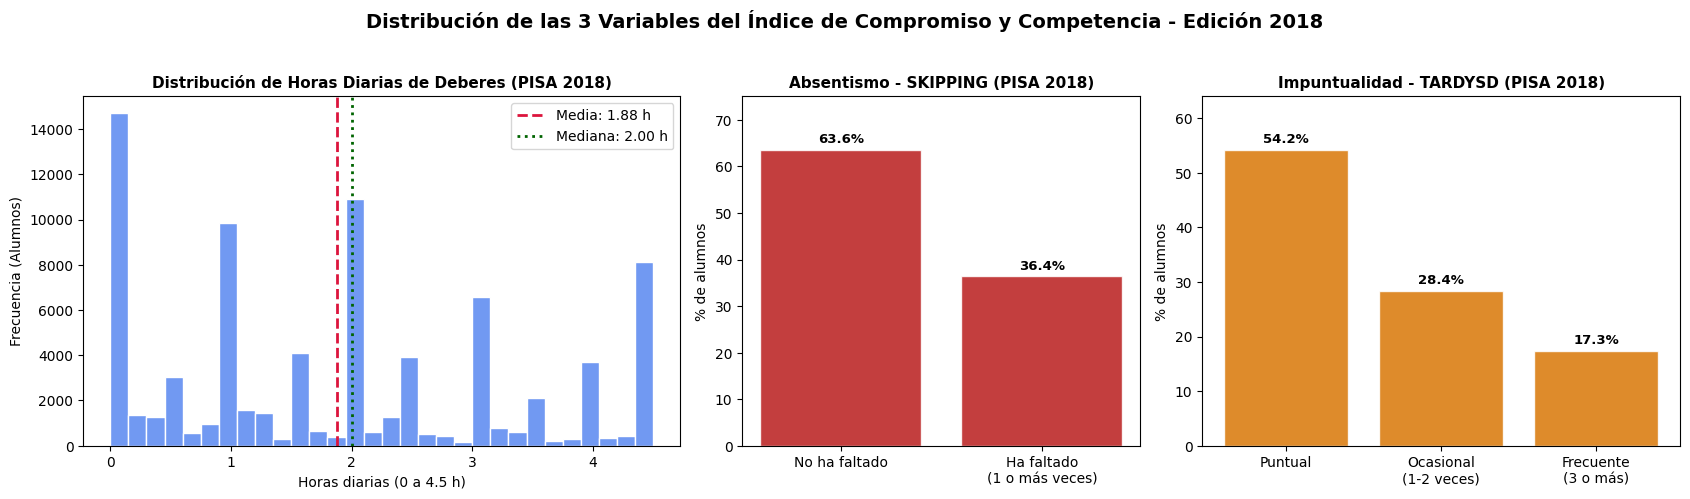

In [117]:
# Comprobación visual de las 3 variables extraídas en PISA 2018
graficar_indicadores_edicion(df_base_2018_alumno, 2018)

# 5. Auditoría de Países y Creación del Índice de Compromiso y Competencia (2012–2022)

Construimos un **índice de compromiso y competencia** comparable entre las cuatro ediciones siguiendo estos pasos:

0. **Paso previo:** auditoría de países con datos faltantes y selección del panel común.
1. **Limpieza a nivel alumno** en cada edición.
2. **Apilado** de las cuatro ediciones en una única matriz.
3. **Ajuste de polaridad** de los comportamientos negativos.
4. **Estandarización global**.
5. **Generación del índice por dos vías:** (A) **Pooled PCA**, con pesos derivados de la varianza compartida, y (B) **índice equiponderado**, con pesos iguales de $1/3$ y los deberes puntuados en U invertida por terciles.
6. **Análisis de sensibilidad del Pooled PCA:** repetición sobre un panel ampliado sin la edición 2018 para comprobar si sus pesos son estables al aumentar la representación de países.
7. **Comparación de ambas vías y elección:** con la evidencia de los pasos 5 y 6, el índice con más sentido metodológico pasa a denominarse **índice de compromiso y competencia**; sobre él se definen los umbrales bajo y alto.
8. **Separación por edición, evaluación en los estratos fijos, evolución longitudinal y exportación** del índice sobre el panel común de $12$ países.

## 5.1 Paso previo: análisis de países con datos faltantes y selección del panel común

💡 **Por qué nos quedamos solo con un panel común de países**

La cobertura de las tres variables no es homogénea: en **2018** el tiempo de deberes procede de un cuestionario opcional y muchos países lo tienen completamente vacío, y algunos países ni siquiera tienen estratos fijos en todas las ediciones. Si construyéramos el índice con los países disponibles en cada año, la composición de la muestra cambiaría de una edición a otra y cualquier tendencia mezclaría cambios reales de comportamiento con cambios en qué países se observan.

Para no falsear el índice ni el futuro modelo, y garantizar una comparabilidad histórica limpia, **nos quedamos únicamente con los países que en TODAS las ediciones (2012, 2015, 2018 y 2022) tienen datos válidos de tiempo de deberes, `SKIPPING` y `TARDYSD`**. Los países que carecen de datos en alguna edición no se tienen en cuenta ni para el modelo ni para las visualizaciones del índice.

Perderemos precisión por tener menos filas, pero lo compensamos con la garantía de que cualquier tendencia es real y libre de sesgos que se producirian por introducir paises inestables en las ediciones.

In [118]:
# Tablas armonizadas de cada edición y variables que conforman el índice
bases_por_edicion = {
    2012: df_base_2012_alumno,
    2015: df_base_2015_alumno,
    2018: df_base_2018_alumno,
    2022: df_base_2022_alumno,
}
ediciones = [2012, 2015, 2018, 2022]
variables_indice = ['tiempo_deberes_totales_diarios', 'SKIPPING', 'TARDYSD']

nombres_cortos = {
    'tiempo_deberes_totales_diarios': 'Deberes',
    'SKIPPING': 'SKIPPING',
    'TARDYSD': 'TARDYSD',
}

# Porcentaje de alumnos con dato válido por país, edición y variable
tablas_cobertura = []
for year, df_edicion in bases_por_edicion.items():
    cobertura = (
        df_edicion.groupby('CNT')[variables_indice]
        .apply(lambda datos: datos.notna().mean() * 100)
        .reset_index()
        .assign(year=year)
    )
    tablas_cobertura.append(cobertura)

df_cobertura = pd.concat(tablas_cobertura, ignore_index=True)

# Matriz País x (Variable, Edición); un país ausente en una edición queda con 0 % de cobertura
matriz_cobertura = (
    df_cobertura
    .pivot(index='CNT', columns='year', values=variables_indice)
    .reindex(columns=pd.MultiIndex.from_product([variables_indice, ediciones]))
    .fillna(0.0)
)

# Un país entra en el panel común si tiene datos válidos en las 3 variables y en las 4 ediciones
cumple_panel = (matriz_cobertura > 0).all(axis=1)
paises_panel = sorted(cumple_panel[cumple_panel].index)
paises_excluidos = sorted(cumple_panel[~cumple_panel].index)

print(f'Países con estrato fijo en alguna edición: {len(matriz_cobertura)}')
print(f'Países que superan el filtro del panel común: {len(paises_panel)}')
print(f'Países excluidos: {len(paises_excluidos)}')

Países con estrato fijo en alguna edición: 32
Países que superan el filtro del panel común: 12
Países excluidos: 20


In [119]:
# Motivo de exclusión de cada país: edición sin estratos fijos o variable sin ningún dato válido
paises_por_edicion = {year: set(df['CNT'].unique()) for year, df in bases_por_edicion.items()}

motivos_exclusion = []
for pais in paises_excluidos:
    ediciones_sin_estrato = [year for year in ediciones if pais not in paises_por_edicion[year]]

    celdas_vacias = [
        f'{nombres_cortos[variable]} {year}'
        for variable, year in matriz_cobertura.columns
        if matriz_cobertura.loc[pais, (variable, year)] == 0 and year not in ediciones_sin_estrato
    ]

    motivos_exclusion.append({
        'País': pais,
        'Ediciones sin estrato fijo': ', '.join(map(str, ediciones_sin_estrato)) or '-',
        'Variables sin ningún dato válido': ', '.join(celdas_vacias) or '-',
    })

print('Motivo de exclusión de los países que no superan el filtro:')
display(pd.DataFrame(motivos_exclusion).set_index('País'))

Motivo de exclusión de los países que no superan el filtro:


,Ediciones sin estrato fijo,Variables sin ningún dato válido
País,,
BEL,"2015, 2018, 2022",-
CAN,"2018, 2022",-
CHE,-,Deberes 2018
CHL,-,Deberes 2018
CZE,-,Deberes 2018
DEU,-,Deberes 2018
EST,-,Deberes 2018
FIN,-,Deberes 2018
FRA,-,Deberes 2018


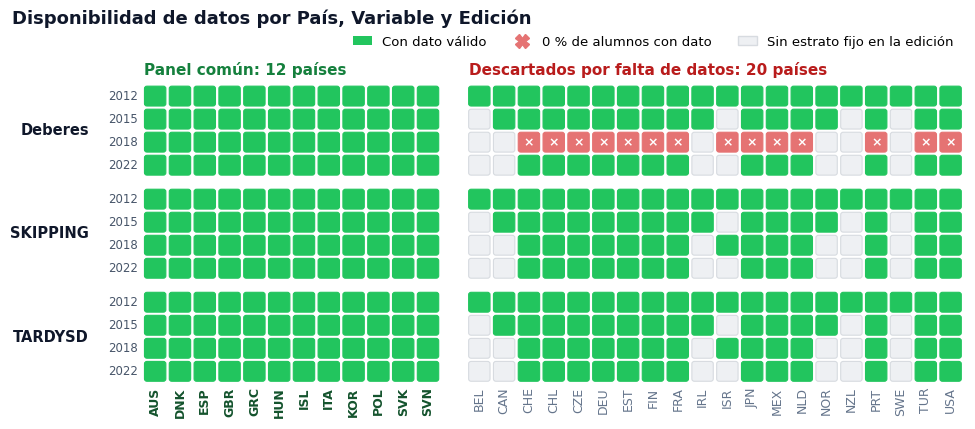

Lista final de países del panel común (12): AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK, SVN


In [120]:


COLOR_DATO = '#22c55e'       # país con dato válido
COLOR_SIN_DATO = '#e57373'   # país con estrato fijo pero 0 % de datos
COLOR_SIN_ESTRATO = '#eef0f3' # país sin estrato fijo en esa edición

lado, hueco, hueco_var, hueco_bloque = 1.0, 0.16, 0.55, 1.4

# Posición horizontal de cada país: bloque izquierdo (panel común) y bloque derecho (excluidos)
posiciones_x = {pais: i * (lado + hueco) for i, pais in enumerate(paises_panel)}
inicio_excluidos = len(paises_panel) * (lado + hueco) - hueco + hueco_bloque
for i, pais in enumerate(paises_excluidos):
    posiciones_x[pais] = inicio_excluidos + i * (lado + hueco)
ancho_total = max(posiciones_x.values()) + lado

# Posición vertical de cada fila (Variable, Edición), con separación entre variables
posiciones_y = {}
y = 0.0
for variable in variables_indice:
    for year in ediciones:
        posiciones_y[(variable, year)] = y
        y -= lado + hueco
    y -= hueco_var
y_base = min(posiciones_y.values())

fig, ax = plt.subplots(figsize=(10, 4.4))
fig.patch.set_facecolor('white')

for (variable, year), y in posiciones_y.items():
    for pais, x in posiciones_x.items():
        if pais not in paises_por_edicion[year]:
            color, borde = COLOR_SIN_ESTRATO, '#d7dbe0'
        elif matriz_cobertura.loc[pais, (variable, year)] > 0:
            color, borde = COLOR_DATO, COLOR_DATO
        else:
            color, borde = COLOR_SIN_DATO, COLOR_SIN_DATO
        ax.add_patch(FancyBboxPatch(
            (x, y), lado, lado, boxstyle='round,pad=0,rounding_size=0.12',
            facecolor=color, edgecolor=borde, linewidth=0.8
        ))
        # Marca secundaria para que el 0 % no dependa solo del color
        if color == COLOR_SIN_DATO:
            ax.text(x + lado / 2, y + lado / 2, '×', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    ax.text(-0.3, y + lado / 2, str(year), ha='right', va='center', fontsize=8.5, color='#475569')

# Nombre de cada variable a la izquierda de su grupo de ediciones
for variable in variables_indice:
    y_centro = (posiciones_y[(variable, ediciones[0])] + posiciones_y[(variable, ediciones[-1])] + lado) / 2
    ax.text(-2.6, y_centro, nombres_cortos[variable], ha='right', va='center',
            fontsize=10.5, fontweight='bold', color='#0f172a')

# Códigos de país bajo cada columna, resaltando los retenidos en el panel común
for pais, x in posiciones_x.items():
    retenido = pais in paises_panel
    ax.text(x + lado / 2, y_base - 0.3, pais, ha='center', va='top', rotation=90, fontsize=9,
            color='#14532d' if retenido else '#64748b', fontweight='bold' if retenido else 'normal')

# Rótulos de los dos bloques
y_sup = posiciones_y[(variables_indice[0], ediciones[0])] + lado
ax.text(0, y_sup + 0.4, f'Panel común: {len(paises_panel)} países', ha='left', va='bottom',
        fontsize=11, fontweight='bold', color='#15803d')
ax.text(inicio_excluidos, y_sup + 0.4, f'Descartados por falta de datos: {len(paises_excluidos)} países',
        ha='left', va='bottom', fontsize=11, fontweight='bold', color='#b91c1c')

leyenda = [
    Patch(facecolor=COLOR_DATO, label='Con dato válido'),
    Line2D([0], [0], marker='X', linestyle='', markersize=10, markerfacecolor=COLOR_SIN_DATO,
           markeredgecolor=COLOR_SIN_DATO, label='0 % de alumnos con dato'),
    Patch(facecolor=COLOR_SIN_ESTRATO, edgecolor='#d7dbe0', label='Sin estrato fijo en la edición'),
]
ax.legend(handles=leyenda, loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=3,
          frameon=False, fontsize=9.5, handlelength=1.4)

ax.set_title('Disponibilidad de datos por País, Variable y Edición', loc='left',
             fontsize=13, fontweight='bold', color='#0f172a', pad=26)
ax.set_xlim(-6.2, ancho_total + 0.2)
ax.set_ylim(y_base - 1.9, y_sup + 1.3)
ax.axis('off')

plt.tight_layout()
plt.show()

print(f'Lista final de países del panel común ({len(paises_panel)}): {", ".join(paises_panel)}')

**Resultado de la auditoría de países:**
* De los $32$ países con estrato fijo en alguna edición, **solo $12$ superan el filtro**: AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK y SVN.
* **El cuello de botella es el tiempo de deberes en 2018:** $13$ países tienen estratos fijos y datos de asistencia en las cuatro ediciones, pero $0\%$ de datos de deberes en 2018 porque no administraron el cuestionario opcional (CHE, CHL, CZE, DEU, EST, FIN, FRA, JPN, MEX, NLD, PRT, TUR y USA).
* Los otros $7$ países excluidos (BEL, CAN, IRL, ISR, NOR, NZL y SWE) no tienen estratos fijos en una o varias ediciones.
* **Caso de GBR:** supera el filtro, pero en 2018 solo el $29\%$ de sus alumnos tiene dato de deberes, frente al $72$–$91\%$ del resto del panel. Su aportación a 2018 procede de una submuestra reducida y debe interpretarse con cautela.
* Con este filtro, la composición de países es idéntica en las cuatro ediciones, de modo que las diferencias entre años no se deben a la entrada o salida de países.

## 5.2 Paso 1: limpieza de datos faltantes a nivel alumno

💡 **¿Por qué eliminamos datos antes del PCA?**

El Análisis de Componentes Principales necesita una matriz completa: no admite valores faltantes y cualquier imputación introduciría información que el alumno no ha declarado. Por eso, tras filtrar por los países del panel común, aplicamos en **cada edición por separado** un filtro estricto `.dropna()` sobre las tres variables (`tiempo_deberes_totales_diarios`, `SKIPPING` y `TARDYSD`). Solo pasan a la siguiente fase los alumnos con datos completos en las tres variables y con estrato fijo asignado.

In [121]:
# Variables obligatorias: las 3 del índice y el estrato fijo
columnas_obligatorias = variables_indice + ['PERFIL_CODE']

bases_limpias = {}
resumen_limpieza = []

for year, df_edicion in bases_por_edicion.items():
    # 1. Nos quedamos solo con los países del panel común
    df_panel = df_edicion[df_edicion['CNT'].isin(paises_panel)]

    # 2. Eliminamos a los alumnos sin dato en alguna de las 3 variables o sin estrato fijo
    df_limpio = df_panel.dropna(subset=columnas_obligatorias).copy()
    bases_limpias[year] = df_limpio

    resumen_limpieza.append({
        'Edición': year,
        'Alumnos con estrato fijo': len(df_edicion),
        'Alumnos en países del panel': len(df_panel),
        'Alumnos completos (3 variables)': len(df_limpio),
        '% Retenido dentro del panel': len(df_limpio) / len(df_panel) * 100,
    })

print('Resumen de la limpieza a nivel alumno por edición:')
display(pd.DataFrame(resumen_limpieza).set_index('Edición'))

Resumen de la limpieza a nivel alumno por edición:


,Alumnos con estrato fijo,Alumnos en países del panel,Alumnos completos (3 variables),% Retenido dentro del panel
Edición,,,,
2012,265820,115762,74666,64.50
2015,178022,78136,69614,89.09
2018,189532,110023,70451,64.03
2022,186094,105078,95158,90.56


## 5.3 Paso 2: juntar y alinear los datos

💡 **Una misma "vara de medir" para toda la década**

Apilamos verticalmente las cuatro ediciones en una única macro-matriz antes de estandarizar y calcular el PCA. Si ajustáramos un PCA distinto en cada año, cada edición tendría sus propios pesos y su propio origen (media 0 en cada año), y un valor de 0 significaría cosas distintas en 2012 y en 2022. Con el apilado, **los pesos y la escala se estiman una sola vez para toda la década**, de modo que un cambio en la puntuación entre ediciones refleja un cambio en el comportamiento declarado y no un cambio en la regla de medida.

In [122]:
# Columnas que se conservan: identificación, edición, estrato fijo, pesos y las 3 variables del índice
columnas_stacking = [
    'CNT', 'CNTSCHID', 'CNTSTUID', 'year',
    'PERFIL_CODE', 'PERFIL_DESC',
    'W_FSTUWT', 'SENWT',
] + variables_indice

# Apilado vertical de las cuatro ediciones limpias
df_compromiso_global = pd.concat(
    [bases_limpias[year][columnas_stacking] for year in ediciones],
    ignore_index=True,
)

# Copia de 2012, 2015 y 2022 para el análisis de sensibilidad sin 2018 (Sección 5.7)
bases_panel_ampliado = {year: bases_por_edicion[year] for year in [2012, 2015, 2022]}

# Liberación de las tablas por edición ya apiladas
del bases_por_edicion, bases_limpias
del df_base_2012_alumno, df_base_2015_alumno, df_base_2018_alumno, df_base_2022_alumno
gc.collect()

print(f'Macro-matriz global apilada: {len(df_compromiso_global):,} alumnos de {df_compromiso_global["CNT"].nunique()} países')
display(df_compromiso_global.groupby('year').size().rename('Alumnos').to_frame())
display(df_compromiso_global.head())

Macro-matriz global apilada: 309,889 alumnos de 12 países


,Alumnos
year,
2012,74666
2015,69614
2018,70451
2022,95158


,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,SKIPPING,TARDYSD
0,AUS,0000001,00001,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.20,1.00,1.00
1,AUS,0000001,00002,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.00,0.00,0.00
2,AUS,0000001,00003,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,4.50,0.00,1.00
3,AUS,0000001,00004,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,1.80,0.00,1.00
4,AUS,0000001,00005,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,2.20,0.00,1.00


## 5.4 Paso 3: ajuste del sentido de las variables (polaridad)

`SKIPPING` y `TARDYSD` miden comportamientos negativos (desapego e indisciplina): un valor alto indica **menos** compromiso. Las multiplicamos por $-1$ antes de introducirlas al modelo para que apunten en la misma dirección positiva que las horas de deberes. Así, una puntuación alta tanto en la componente principal como en el índice de compromiso y competencia significará **más compromiso**. El tiempo de deberes no se invierte: su puntuación en U invertida se define en la Sección 5.6.2.

In [123]:
# Inversión del signo de los comportamientos negativos
df_compromiso_global['SKIPPING_inv'] = df_compromiso_global['SKIPPING'] * -1
df_compromiso_global['TARDYSD_inv'] = df_compromiso_global['TARDYSD'] * -1

# Variables de entrada al modelo, todas orientadas hacia "más compromiso"
variables_pca = ['tiempo_deberes_totales_diarios', 'SKIPPING_inv', 'TARDYSD_inv']

# Comprobación: tras la inversión ninguna correlación debería ser claramente negativa
print('Correlaciones de Spearman entre las 3 variables tras el ajuste de polaridad:')
display(df_compromiso_global[variables_pca].corr(method='spearman'))

Correlaciones de Spearman entre las 3 variables tras el ajuste de polaridad:


,tiempo_deberes_totales_diarios,SKIPPING_inv,TARDYSD_inv
tiempo_deberes_totales_diarios,1.00,0.02,0.08
SKIPPING_inv,0.02,1.00,0.27
TARDYSD_inv,0.08,0.27,1.00


## 5.5 Paso 4: estandarización global 

Aplicamos un `StandardScaler` a las tres variables sobre la matriz conjunta. La media y la desviación típica se calculan sobre **toda la década a la vez**, sin distinguir a qué edición pertenece cada alumno. Por eso, después de estandarizar, la media global es 0, pero la media de cada edición puede ser distinta de 0: esa diferencia es precisamente la evolución temporal que queremos conservar.

In [124]:
# Ajuste del escalador sobre toda la matriz global (sin agrupar por edición)
escalador_global = StandardScaler()
matriz_estandarizada = escalador_global.fit_transform(df_compromiso_global[variables_pca])

# Guardamos las variables estandarizadas en la propia tabla
columnas_z = [f'z_{variable}' for variable in variables_pca]
df_compromiso_global[columnas_z] = matriz_estandarizada

# Parámetros globales que ha usado el escalador
parametros_escalador = pd.DataFrame({
    'Media global': escalador_global.mean_,
    'Desv. típica global': escalador_global.scale_,
}, index=variables_pca)

print('Parámetros de la estandarización global (década completa):')
display(parametros_escalador)

# Medias por edición tras estandarizar (no tienen por qué ser 0)
print('Media de las variables estandarizadas en cada edición:')
display(df_compromiso_global.groupby('year')[columnas_z].mean())

Parámetros de la estandarización global (década completa):


,Media global,Desv. típica global
tiempo_deberes_totales_diarios,1.77,1.34
SKIPPING_inv,-0.38,0.48
TARDYSD_inv,-0.54,0.72


Media de las variables estandarizadas en cada edición:


,z_tiempo_deberes_totales_diarios,z_SKIPPING_inv,z_TARDYSD_inv
year,,,
2012,-0.16,0.03,0.13
2015,0.25,-0.03,-0.00
2018,0.09,-0.02,-0.09
2022,-0.12,0.01,-0.04


## 5.6 Paso 5: generación del índice por dos vías

A partir de la misma matriz estandarizada (Sección 5.5) generamos dos índices candidatos que resumen las tres dimensiones en una única puntuación por alumno:

* **Vía A: Pooled PCA (Sección 5.6.1).** Los pesos de cada dimensión los decide el propio dato: la primera componente principal pondera cada variable según la varianza que comparte con las demás. Las tres variables entran de forma lineal.
* **Vía B: índice equiponderado (Sección 5.6.2).** Los pesos se fijan de antemano ($1/3$ para cada dimensión) y el tiempo de deberes se puntúa en **U invertida** por terciles, recogiendo la relación no lineal entre horas y rendimiento observada en la Sección 2.2.

En la Sección 5.7 sometemos el Pooled PCA a un análisis de sensibilidad con un panel ampliado de países y en la Sección 5.8 comparamos ambas vías para elegir la que tiene más sentido metodológico. **El índice ganador es el que se denominará índice de compromiso y competencia** y el otro se conserva solo como referencia.

### 5.6.1 Vía A: Pooled PCA

Ajustamos un `PCA(n_components=1)` sobre el bloque único de datos estandarizados. Las puntuaciones de la primera componente principal se guardan en la columna `Indice_PCA`, primera candidata a índice. Como el signo de una componente principal es arbitrario, comprobamos la dirección de las cargas (*loadings*) y, si fuera necesario, invertimos la componente para que los valores positivos signifiquen más horas de deberes y menos absentismo e impuntualidad.

In [125]:
# Ajuste del PCA de una componente sobre la matriz global estandarizada
pca_compromiso = PCA(n_components=1, random_state=42)
puntuaciones_pca = pca_compromiso.fit_transform(matriz_estandarizada)[:, 0]

cargas_pca = pd.Series(pca_compromiso.components_[0], index=variables_pca)

# Verificación de la dirección: la componente debe crecer con el compromiso
if cargas_pca.sum() < 0:
    cargas_pca = -cargas_pca
    puntuaciones_pca = -puntuaciones_pca

df_compromiso_global['Indice_PCA'] = puntuaciones_pca

# Resumen de las cargas factoriales y de la varianza explicada
tabla_cargas = pd.DataFrame({
    'Carga (loading)': cargas_pca,
    'Peso relativo (%)': cargas_pca.abs() / cargas_pca.abs().sum() * 100,
})
tabla_cargas.index = ['Horas de deberes', 'Absentismo invertido (-SKIPPING)', 'Impuntualidad invertida (-TARDYSD)']

varianza_explicada = pca_compromiso.explained_variance_ratio_[0] * 100

print('Cargas factoriales del Pooled PCA (primera componente):')
display(tabla_cargas)
print(f'Varianza explicada por la primera componente: {varianza_explicada:.2f} %')
print(f'Autovalor de la primera componente: {pca_compromiso.explained_variance_[0]:.3f}')
print(f'Todas las cargas son positivas: {bool((cargas_pca > 0).all())}')

Cargas factoriales del Pooled PCA (primera componente):


,Carga (loading),Peso relativo (%)
Horas de deberes,0.19,12.10
Absentismo invertido (-SKIPPING),0.69,43.40
Impuntualidad invertida (-TARDYSD),0.70,44.50


Varianza explicada por la primera componente: 43.27 %
Autovalor de la primera componente: 1.298
Todas las cargas son positivas: True


<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Nota metodológica: alcance de la muestra
  </strong>
  Las dos vías (Pooled PCA e índice equiponderado) se construyen exclusivamente sobre el <b>panel común estricto de los 12 países de la OCDE</b> (AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK y SVN) que no presentan valores nulos estructurales en ninguna de las variables y ediciones evaluadas (Sección 5.1). Al mantener idéntica la composición de países en 2012, 2015, 2018 y 2022, se evita el <b>sesgo de composición longitudinal</b>: las diferencias entre ediciones no pueden atribuirse a la entrada o salida de países.
</div>

💡 **Interpretación psicométrica del Pooled PCA**

* **Autovalor ($\lambda_1 = 1{,}298$):** al ser superior a $1$ (criterio de Kaiser), confirma que la primera componente retiene más información que cualquiera de las tres variables estandarizadas por separado (cada una aporta exactamente $1$ unidad de varianza).
* **Varianza explicada ($43{,}27\%$):** esta única dirección principal captura el $43{,}27\%$ de todas las diferencias de comportamiento presentes en la matriz apilada.

**Formulación del índice PCA (ponderación por varianza compartida):**

$$\text{Indice\_PCA}_i = 0{,}191 \cdot z(\text{Deberes})_i + 0{,}685 \cdot z(-\text{SKIPPING})_i + 0{,}703 \cdot z(-\text{TARDYSD})_i$$

donde $z(\cdot)$ es la estandarización con la media y la desviación típica de toda la década (Sección 5.5).

### 5.6.2 Vía B: índice equiponderado con deberes en U invertida

**¿Cómo se construye el índice equiponderado?**

1. **Deberes en U invertida por terciles.** Dividimos las horas de deberes en terciles **dentro de cada edición**, con cortes ponderados por `SENWT`, y asignamos una puntuación parabólica:
   * **Tercil 1 (pocas horas) = 0:** penaliza la falta de esfuerzo en casa.
   * **Tercil 2 (horas medias) = 1:** premia la zona de eficiencia.
   * **Tercil 3 (exceso de horas) = 0:** penaliza la ineficiencia, es decir, necesitar un número desproporcionado de horas.

   Los terciles se calculan por edición porque la pregunta de deberes cambia entre ciclos (Sección 3.1): así, el tercil refleja la posición relativa del alumno y no el instrumento. En la versión sin ponderar, el tercil central de 2022 terminaba exactamente en $1{,}50$ h diarias, el máximo de rendimiento observado en la Sección 2.2; la tabla de cortes compara ambas versiones.
2. **Suma de tercios.** Estandarizamos la puntuación de deberes con la escala de toda la década (media y DT ponderadas por `SENWT`) y la sumamos, con el mismo peso, a las dos variables de asistencia ya estandarizadas:

$$\text{Indice\_Equiponderado}_i = \tfrac{1}{3}\, z(\text{Deberes en U})_i + \tfrac{1}{3}\, z(-\text{SKIPPING})_i + \tfrac{1}{3}\, z(-\text{TARDYSD})_i$$

3. **Reescalado final.** Reestandarizamos el resultado para que tenga media $0$ y desviación típica $1$ ponderadas sobre toda la década. Así los umbrales se expresan directamente en desviaciones típicas (DT) y son los mismos en todas las ediciones y estratos fijos.

#### Metodología del Índice Equiponderado

💡 **Puntuación parabólica y peso equiponderado: dos pasos compatibles**

No existe contradicción entre transformar los deberes con una lógica parabólica y ponderar el índice a partes iguales, porque ambas decisiones actúan en **momentos distintos** de la construcción:

1. **Transformación (qué mide la variable).** Las horas de deberes no se relacionan de forma lineal con el rendimiento, sino en U invertida como vimos con anterioridad. Por ello, se recodifican en una métrica de **eficiencia**: $0$ para pocas horas (tercil 1), $1$ para horas medias u óptimas (tercil 2) y $0$ para exceso de horas (tercil 3). La forma parabólica se resuelve en este paso, antes de agregar.
2. **Agregación (cuánto pesa la variable).** Una vez creada, la métrica de eficiencia se estandariza ($z$) como cualquier otra dimensión y recibe exactamente el mismo peso que el absentismo y la impuntualidad: $	\frac{1}{3}$ cada una. La suma final es, por tanto, lineal y equiponderada.

En consecuencia, la parábola define el **contenido** de la dimensión de deberes y el equiponderado define su **contribución** al índice. La estandarización previa garantiza que el peso nominal de $ \frac{1}{3}$ sea también un peso efectivo, sin que ninguna dimensión domine por su escala, de modo que el índice resulta comparable entre ediciones y estratos fijos.

#### Ponderación por el peso de senado (`SENWT`)

💡 **Por qué los terciles y la estandarización se ponderan por `SENWT`**

* **Sin ponderar, los países con más alumnos en la muestra fijan los cortes.** Los terciles se calculan con todos los alumnos del panel en cada edición. Si cada alumno cuenta igual, un país con una muestra grande arrastra los cortes hacia sus propias horas de deberes y el "tercil central" pasa a reflejar sobre todo a ese país. Es un efecto del diseño muestral, no del comportamiento de los alumnos.
* **`SENWT` iguala el peso de los países.** El peso de senado suma lo mismo en cada país, de modo que cada país aporta lo mismo al resultado, tenga $4.000$ o $30.000$ alumnos evaluados. El peso no multiplica la puntuación del alumno: se usa al calcular los cortes, como peso acumulado, y al calcular medias y desviaciones típicas.
* **Se pondera toda la construcción, no solo los terciles.** Los cortes de los terciles, la estandarización de las tres dimensiones y el reescalado final usan `SENWT`. Así, la media $0$ del índice es la media de la década con todos los países pesando igual, y es coherente con las medias ponderadas que se presentan en la Sección 5.9.
* **La puntuación de cada alumno sigue siendo individual.** El índice no se multiplica por el peso; `SENWT` se exporta como columna aparte para usarlo como `sample_weight` en el modelado.

In [126]:
# Variables de entrada del índice equiponderado: deberes puntuados en U invertida y asistencia con polaridad invertida
variables_indice_cc = ['deberes_en_u', 'SKIPPING_inv', 'TARDYSD_inv']


def cuantiles_ponderados(valores, pesos, probabilidades):
    """Cuantiles ponderados: primer valor en el que el peso acumulado alcanza cada probabilidad."""
    orden = np.argsort(valores.to_numpy(), kind='stable')
    valores_ordenados = valores.to_numpy()[orden]
    peso_acumulado = np.cumsum(pesos.to_numpy()[orden]) / pesos.sum()
    return [valores_ordenados[np.searchsorted(peso_acumulado, p)] for p in probabilidades]


def tercil_deberes_edicion(datos_edicion):
    """Tercil (1, 2, 3) de las horas de deberes dentro de una edición, con cortes ponderados por SENWT; los empates caen en el mismo tercil."""
    horas = datos_edicion['tiempo_deberes_totales_diarios']
    cortes = cuantiles_ponderados(horas, datos_edicion['SENWT'], [1 / 3, 2 / 3])
    return pd.cut(horas, [-np.inf, *cortes, np.inf], labels=[1, 2, 3]).astype(int)


def construir_indice_equiponderado(tabla):
    """
    Índice equiponderado: suma de tercios de deberes en U invertida, -SKIPPING y -TARDYSD.
    Tercil 1 = 0 | Tercil 2 = 1 | Tercil 3 = 0. Terciles, estandarización y reescalado final ponderados por SENWT,
    de modo que cada país pesa lo mismo; resultado con media 0 y DT 1 ponderadas sobre la tabla completa.
    """
    pesos = tabla['SENWT']
    tabla['tercil_deberes'] = pd.concat(
        [tercil_deberes_edicion(datos_edicion) for _, datos_edicion in tabla.groupby('year')]
    )
    tabla['deberes_en_u'] = (tabla['tercil_deberes'] == 2).astype(float)

    # Estandarización global ponderada de las 3 dimensiones y suma con peso 1/3 cada una
    escalador = StandardScaler().fit(tabla[variables_indice_cc], sample_weight=pesos)
    suma_tercios = escalador.transform(tabla[variables_indice_cc]).mean(axis=1)

    # Reescalado final a media 0 y DT 1 ponderadas
    media = np.average(suma_tercios, weights=pesos)
    desviacion = np.sqrt(np.average((suma_tercios - media) ** 2, weights=pesos))
    return (suma_tercios - media) / desviacion


df_compromiso_global['Indice_Equiponderado'] = construir_indice_equiponderado(df_compromiso_global)

# Cortes de los terciles de deberes en cada edición: ponderados por SENWT (los usados) frente a sin ponderar
cortes_terciles = pd.DataFrame({
    year: [
        *cuantiles_ponderados(datos['tiempo_deberes_totales_diarios'], datos['SENWT'], [1 / 3, 2 / 3]),
        *datos['tiempo_deberes_totales_diarios'].quantile([1 / 3, 2 / 3]),
    ]
    for year, datos in df_compromiso_global.groupby('year')
}, index=['Fin tercil 1 (h)', 'Fin tercil 2 (h)', 'Fin tercil 1 sin ponderar (h)', 'Fin tercil 2 sin ponderar (h)']).T

print('Cortes de los terciles de horas diarias de deberes por edición (ponderados por SENWT frente a sin ponderar):')
display(cortes_terciles)

Cortes de los terciles de horas diarias de deberes por edición (ponderados por SENWT frente a sin ponderar):


,Fin tercil 1 (h),Fin tercil 2 (h),Fin tercil 1 sin ponderar (h),Fin tercil 2 sin ponderar (h)
2012,0.60,1.60,0.80,1.80
2015,1.20,2.60,1.20,2.60
2018,1.00,2.50,1.00,2.50
2022,0.75,1.50,0.75,1.50


## 5.7 Paso 6: análisis de sensibilidad del Pooled PCA con el panel ampliado sin 2018

Antes de elegir entre ambas vías, comprobamos si los pesos del Pooled PCA se mantienen cuando cambia la composición de países. Para ello eliminamos el cuello de botella de la edición 2018 y repetimos los pasos 1 a 5 de la construcción sobre un **Panel Ampliado** con las ediciones 2012, 2015 y 2022. Este panel solo se utiliza como prueba de robustez: el índice que se exporta en la Sección 5.9 se construye sobre el panel común de $12$ países con las cuatro ediciones.

### 5.7.1 Re-evaluación del panel balanceado sin 2018

💡 **2018 actúa como un embudo para la muestra**

Exigir continuidad en las cuatro ediciones obliga a que cada país tenga datos de deberes en 2018, y en esa edición el tiempo de deberes (`OUTHOURS`, armonizado como `tiempo_deberes_totales_diarios`) procede de un cuestionario opcional con nulos masivos. Ese único requisito deja el estudio en un panel reducido de **12 países** (Sección 5.1), aunque muchos de los descartados tienen datos completos en el resto de ediciones.

Para medir el coste de esa decisión, excluimos 2018 temporalmente y construimos un **Panel Ampliado** cruzando únicamente las ediciones **2012, 2015 y 2022**. El panel sigue siendo balanceado: un país solo entra si tiene alumnos con datos válidos en `Deberes`, `SKIPPING` y `TARDYSD` y estrato fijo en las tres ediciones a la vez.

In [127]:
# Ediciones del panel ampliado: se excluye 2018 por los nulos masivos en el tiempo de deberes
ediciones_sin2018 = [2012, 2015, 2022]

# Alumnos con las 3 variables del índice y el estrato fijo completos en cada edición
bases_completas_sin2018 = {
    year: bases_panel_ampliado[year].dropna(subset=columnas_obligatorias)
    for year in ediciones_sin2018
}

# Países con datos válidos simultáneamente en 2012, 2015 y 2022
paises_panel_ampliado = sorted(set.intersection(
    *(set(df_edicion['CNT']) for df_edicion in bases_completas_sin2018.values())
))
paises_recuperados = sorted(set(paises_panel_ampliado) - set(paises_panel))

print(f'Panel común con 2018: {len(paises_panel)} países')
print(f'Panel ampliado sin 2018: {len(paises_panel_ampliado)} países')
print(f'Países recuperados: {len(paises_recuperados)} -> {", ".join(paises_recuperados)}')
print(f'Lista completa del panel ampliado: {", ".join(paises_panel_ampliado)}')

Panel común con 2018: 12 países
Panel ampliado sin 2018: 25 países
Países recuperados: 13 -> CHE, CHL, CZE, DEU, EST, FIN, FRA, JPN, MEX, NLD, PRT, TUR, USA
Lista completa del panel ampliado: AUS, CHE, CHL, CZE, DEU, DNK, ESP, EST, FIN, FRA, GBR, GRC, HUN, ISL, ITA, JPN, KOR, MEX, NLD, POL, PRT, SVK, SVN, TUR, USA


### 5.7.2 Apilamiento y ajuste de polaridad del panel ampliado

In [128]:
# Apilado vertical de los alumnos completos del panel ampliado en 2012, 2015 y 2022
df_compromiso_sin2018 = pd.concat(
    [
        df_edicion.loc[df_edicion['CNT'].isin(paises_panel_ampliado), columnas_stacking]
        for df_edicion in bases_completas_sin2018.values()
    ],
    ignore_index=True,
)

del bases_panel_ampliado, bases_completas_sin2018
gc.collect()

# Inversión del signo de los comportamientos negativos
df_compromiso_sin2018['SKIPPING_inv'] = df_compromiso_sin2018['SKIPPING'] * -1
df_compromiso_sin2018['TARDYSD_inv'] = df_compromiso_sin2018['TARDYSD'] * -1

# Alumnos por edición en ambos paneles
comparativa_muestra = pd.DataFrame({
    'Alumnos panel común (con 2018)': df_compromiso_global.groupby('year').size(),
    'Alumnos panel ampliado (sin 2018)': df_compromiso_sin2018.groupby('year').size(),
}).astype('Int64')

print(f'Macro-matriz del panel ampliado: {len(df_compromiso_sin2018):,} alumnos de {df_compromiso_sin2018["CNT"].nunique()} países')
display(comparativa_muestra)

Macro-matriz del panel ampliado: 440,984 alumnos de 25 países


,Alumnos panel común (con 2018),Alumnos panel ampliado (sin 2018)
year,,
2012,74666,137990
2015,69614,134880
2018,70451,<NA>
2022,95158,168114


### 5.7.3 Cálculo vectorizado de los índices competidores

Aplicamos la misma secuencia que en las Secciones 5.5 a 5.6: un `StandardScaler` ajustado sobre la matriz conjunta de los 3 años y, a partir de ella, dos índices:

* **`Indice_PCA_Sin2018`:** puntuaciones de la primera componente de un `PCA(n_components=1)`, con el signo orientado hacia "más compromiso".
* **`Indice_Equiponderado_Sin2018`:** índice equiponderado construido con la misma función de la Sección 5.6.2 (deberes en U invertida por terciles de cada edición y peso de $1/3$ para cada dimensión).

In [129]:
# Estandarización global sobre la matriz conjunta de 2012, 2015 y 2022
escalador_sin2018 = StandardScaler()
matriz_z_sin2018 = escalador_sin2018.fit_transform(df_compromiso_sin2018[variables_pca])
df_compromiso_sin2018[columnas_z] = matriz_z_sin2018

# Índice PCA robusto: primera componente principal del panel ampliado
pca_sin2018 = PCA(n_components=1, random_state=42)
puntuaciones_sin2018 = pca_sin2018.fit_transform(matriz_z_sin2018)[:, 0]
cargas_sin2018 = pd.Series(pca_sin2018.components_[0], index=variables_pca)

# Verificación de la dirección: la componente debe crecer con el compromiso
if cargas_sin2018.sum() < 0:
    cargas_sin2018 = -cargas_sin2018
    puntuaciones_sin2018 = -puntuaciones_sin2018

df_compromiso_sin2018['Indice_PCA_Sin2018'] = puntuaciones_sin2018

# Índice equiponderado con la misma construcción que en la Sección 5.6.2
df_compromiso_sin2018['Indice_Equiponderado_Sin2018'] = construir_indice_equiponderado(df_compromiso_sin2018)

# Comparativa de los pesos frente al Pooled PCA del panel común con 2018
comparativa_cargas = pd.DataFrame({
    'Carga con 2018': cargas_pca.to_numpy(),
    'Carga sin 2018': cargas_sin2018.to_numpy(),
    'Peso relativo con 2018 (%)': tabla_cargas['Peso relativo (%)'].to_numpy(),
    'Peso relativo sin 2018 (%)': (cargas_sin2018.abs() / cargas_sin2018.abs().sum() * 100).to_numpy(),
}, index=tabla_cargas.index)
comparativa_cargas['Variación del peso (p.p.)'] = (
    comparativa_cargas['Peso relativo sin 2018 (%)'] - comparativa_cargas['Peso relativo con 2018 (%)']
)

print('Cargas factoriales del PCA: panel común (con 2018) vs. panel ampliado (sin 2018):')
display(comparativa_cargas.style.format('{:.3f}'))
print(f'Varianza explicada por la PC1 sin 2018: {pca_sin2018.explained_variance_ratio_[0] * 100:.2f} % '
      f'(con 2018: {varianza_explicada:.2f} %)')
print(f'Autovalor de la PC1 sin 2018: {pca_sin2018.explained_variance_[0]:.3f} '
      f'(con 2018: {pca_compromiso.explained_variance_[0]:.3f})')

Cargas factoriales del PCA: panel común (con 2018) vs. panel ampliado (sin 2018):


,Carga con 2018,Carga sin 2018,Peso relativo con 2018 (%),Peso relativo sin 2018 (%),Variación del peso (p.p.)
Horas de deberes,0.191,0.041,12.102,2.814,-9.287
Absentismo invertido (-SKIPPING),0.685,0.704,43.399,48.440,5.042
Impuntualidad invertida (-TARDYSD),0.703,0.709,44.500,48.745,4.246


Varianza explicada por la PC1 sin 2018: 42.34 % (con 2018: 43.27 %)
Autovalor de la PC1 sin 2018: 1.270 (con 2018: 1.298)


💡 **¿Cambia el peso de las horas de deberes con la entrada de nuevos países?**

* **Sí, y a la baja:** la carga de los deberes cae de $0{,}191$ a $0{,}041$ y su peso relativo pasa del $12{,}1\%$ al $2{,}8\%$ ($-9{,}3$ p.p.). Ese peso se lo reparten el absentismo ($48{,}4\%$) y la impuntualidad ($48{,}7\%$).
* **La parte de asistencia es estable:** sus cargas apenas se mueven ($0{,}685 \rightarrow 0{,}704$ y $0{,}703 \rightarrow 0{,}709$), el autovalor sigue por encima del criterio de Kaiser ($\lambda_1 = 1{,}270$ frente a $1{,}298$) y la varianza explicada es prácticamente la misma ($42{,}34\%$ frente a $43{,}27\%$).
* **Lectura:** con $25$ países, los deberes comparten todavía menos varianza con la asistencia y el PCA los descarta casi por completo. El `Indice_PCA_Sin2018` pasa a ser, en la práctica, un índice de asistencia y puntualidad.

### 5.7.4 **Conclusiones del análisis de sensibilidad**


* **Ganancia de muestra:** al eliminar 2018, el panel balanceado pasa de $12$ a $25$ países. Se recuperan los $13$ países que la Sección 5.1 descartaba solo por no tener datos de deberes en 2018 (CHE, CHL, CZE, DEU, EST, FIN, FRA, JPN, MEX, NLD, PRT, TUR y USA). El número de alumnos casi se duplica en cada edición: $137.990$ en 2012 (antes $74.666$), $134.880$ en 2015 (antes $69.614$) y $168.114$ en 2022 (antes $95.158$), para un total de $440.984$ alumnos.

* **Estabilidad matemática:** la estructura de la asistencia es robusta, ya que el absentismo y la impuntualidad pesan lo mismo con 12 que con 25 países. Lo que no es estable es el peso de los deberes en el PCA, que pasa del $12{,}1\%$ al $2{,}8\%$ según qué países formen el panel. El índice equiponderado no tiene este problema: sus pesos son fijos y su correlación con la puntuación de deberes en U es prácticamente la misma en ambos paneles ($0{,}547$ frente a $0{,}55$).


* **Consecuencia para el Pooled PCA:** al aumentar la representación de países, el peso de los deberes se vuelve residual y el PCA pasa a ser, en la práctica, un índice de asistencia y puntualidad. Un índice cuya dimensión de esfuerzo en casa depende de qué países formen el panel no es fiable para medir compromiso y competencia; este resultado es el argumento central de la elección en la Sección 5.8.

## 5.8 Paso 7: comparación de ambas vías y elección del índice

Con los dos índices construidos sobre el panel común (Sección 5.6) y el Pooled PCA sometido al análisis de sensibilidad (Sección 5.7), los comparamos en tres aspectos: el peso que recibe cada dimensión, lo bien que cada índice recoge las tres variables de partida y la estabilidad de esos pesos. La elección se justifica al final de la sección, una vez reunida toda la evidencia.

### 5.8.1 Pesos de cada dimensión

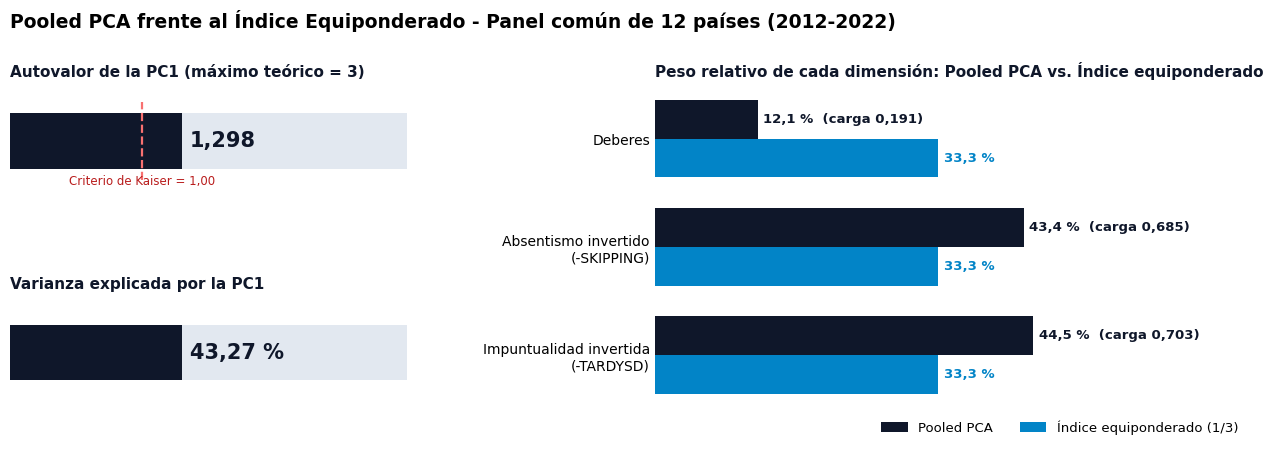

In [130]:
# Mini-dashboard del Pooled PCA: métricas de extracción (izquierda) y pesos frente al índice equiponderado (derecha)
autovalor_pc1 = pca_compromiso.explained_variance_[0]
UMBRAL_KAISER = 1.0
COLOR_PCA, COLOR_CC, COLOR_PISTA = '#0f172a', '#0284c7', '#e2e8f0'

fig = plt.figure(figsize=(16, 4.2))
rejilla = fig.add_gridspec(2, 2, width_ratios=[1, 1.5], hspace=0.9, wspace=0.5)
ax_autovalor = fig.add_subplot(rejilla[0, 0])
ax_varianza = fig.add_subplot(rejilla[1, 0])
ax_pesos = fig.add_subplot(rejilla[:, 1])

# --- Panel izquierdo: medidores del autovalor (máximo teórico = nº de variables) y de la varianza explicada ---
medidores = [(ax_autovalor, autovalor_pc1, len(variables_pca), formato_es(autovalor_pc1, 3), 'Autovalor de la PC1 (máximo teórico = 3)'),
             (ax_varianza, varianza_explicada, 100, f'{formato_es(varianza_explicada, 2)} %', 'Varianza explicada por la PC1'),
]
for ax, valor, maximo, texto, titulo in medidores:
    ax.barh(0, maximo, height=0.5, color=COLOR_PISTA)
    ax.barh(0, valor, height=0.5, color=COLOR_PCA)
    ax.text(valor + maximo * 0.02, 0, texto, ha='left', va='center', fontsize=15, fontweight='bold', color=COLOR_PCA)
    ax.set_title(titulo, loc='left', fontsize=11, fontweight='bold', color='#0f172a')
    ax.set_xlim(0, maximo)
    ax.set_ylim(-0.5, 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    for borde in ax.spines.values():
        borde.set_visible(False)

# Referencia del criterio de Kaiser sobre el medidor del autovalor
ax_autovalor.axvline(UMBRAL_KAISER, ymin=0.15, ymax=0.85, color='#f87171', linestyle='--', linewidth=1.6)
ax_autovalor.text(UMBRAL_KAISER, -0.3, 'Criterio de Kaiser = 1,00', ha='center', va='top', fontsize=8.5, color='#b91c1c')

# --- Panel derecho: peso relativo de cada dimensión en ambos índices ---
etiquetas_variables = ['Deberes', 'Absentismo invertido\n(-SKIPPING)', 'Impuntualidad invertida\n(-TARDYSD)']
pesos_pca = tabla_cargas['Peso relativo (%)'].to_numpy()
pesos_cc = np.full(len(etiquetas_variables), 100 / len(etiquetas_variables))
posiciones = np.arange(len(etiquetas_variables))
alto_barra = 0.36

barras_pca = ax_pesos.barh(posiciones - alto_barra / 2, pesos_pca, height=alto_barra, color=COLOR_PCA, label='Pooled PCA')
barras_cc = ax_pesos.barh(posiciones + alto_barra / 2, pesos_cc, height=alto_barra, color=COLOR_CC, label='Índice equiponderado (1/3)')

etiquetas_pca = [
    f'{formato_es(peso, 1)} %  (carga {formato_es(carga, 3)})'
    for peso, carga in zip(pesos_pca, tabla_cargas['Carga (loading)'])
]
ax_pesos.bar_label(barras_pca, labels=etiquetas_pca, padding=4, fontsize=9.5, fontweight='bold', color=COLOR_PCA)
ax_pesos.bar_label(barras_cc, labels=[f'{formato_es(peso, 1)} %' for peso in pesos_cc],
                   padding=4, fontsize=9.5, fontweight='bold', color=COLOR_CC)

ax_pesos.set_yticks(posiciones)
ax_pesos.set_yticklabels(etiquetas_variables, fontsize=10)
ax_pesos.invert_yaxis()
ax_pesos.set_xlim(0, 70)
ax_pesos.set_xticks([])
ax_pesos.tick_params(axis='y', length=0)
for borde in ax_pesos.spines.values():
    borde.set_visible(False)
ax_pesos.set_title('Peso relativo de cada dimensión: Pooled PCA vs. Índice equiponderado', loc='left',
                   fontsize=11, fontweight='bold', color='#0f172a')
ax_pesos.legend(loc='upper right', bbox_to_anchor=(1.0, 0.0), ncol=2, fontsize=9.5, frameon=False)

plt.suptitle(
    f'Pooled PCA frente al Índice Equiponderado - Panel común de {len(paises_panel)} países (2012-2022)',
    fontsize=13.5, fontweight='bold', x=0.125, ha='left', y=1.06
)
plt.show()

### 5.8.2 Qué recoge cada índice de las variables de partida

In [131]:
# Los dos índices candidatos
indices_candidatos = ['Indice_Equiponderado', 'Indice_PCA']

# Correlación entre ambos índices
correlacion_indices = df_compromiso_global[indices_candidatos].corr().iloc[0, 1]
print(f'Correlación de Pearson entre el índice equiponderado y el Pooled PCA: {correlacion_indices:.3f}')

# Cuánto refleja cada índice cada una de las variables de partida
print('Correlación de cada índice con las variables estandarizadas de partida:')
display(
    df_compromiso_global[columnas_z + ['deberes_en_u'] + indices_candidatos]
    .corr()
    .loc[columnas_z + ['deberes_en_u'], indices_candidatos]
)

Correlación de Pearson entre el índice equiponderado y el Pooled PCA: 0.835
Correlación de cada índice con las variables estandarizadas de partida:


,Indice_Equiponderado,Indice_PCA
z_tiempo_deberes_totales_diarios,0.00,0.22
z_SKIPPING_inv,0.69,0.78
z_TARDYSD_inv,0.68,0.80
deberes_en_u,0.54,0.01


**Comparación Pooled PCA frente al índice equiponderado:**
* Los dos índices ordenan a los alumnos de forma parecida ($r = 0,84$), porque comparten la señal de asistencia: las correlaciones con absentismo e impuntualidad invertidos son de $0,68$ y $0,69$ en el índice equiponderado y de $0,78$ y $0,80$ en el PCA.
* La diferencia está en los deberes. El índice PCA apenas los recoge: su correlación es de $0,22$ con las horas y de $0,02$ con la puntuación en U. El índice equiponderado tiene una correlación de $0,55$ con la puntuación en U y de $0,02$ con las horas en escala lineal: no premia hacer más horas, sino estar en la zona óptima.

### 5.8.3 Elección del índice

💡 **Comparación metodológica: Pooled PCA frente al índice equiponderado**

* **El PCA margina los deberes por ortogonalidad.** El PCA reparte los pesos según la varianza compartida. Absentismo e impuntualidad están correlacionados entre sí ($\rho = 0{,}27$), mientras que los deberes son prácticamente ortogonales a ambos ($\rho = 0{,}02$ y $0{,}08$). Por eso la primera componente, con autovalor $\lambda_1 = 1{,}298$, se orienta casi por completo hacia la asistencia: los deberes reciben una carga de solo $0{,}191$ ($12{,}1\%$ del peso), por debajo del umbral habitual de $|0{,}30|$–$|0{,}40|$ para considerar que una variable forma parte del constructo. El resultado es, en la práctica, un índice de asistencia.

* **El peso del PCA no es estable.** En el panel ampliado sin 2018 (Sección 5.7), con $25$ países, la carga de los deberes cae del $12{,}1\%$ al $2{,}8\%$ solo por cambiar los países de la muestra, y el PCA queda reducido a un índice de asistencia. Una ponderación que depende de la composición del panel no mide de forma fiable el esfuerzo en casa.

* **El PCA asume relaciones lineales.** Cada variable entra con un único peso, de modo que más horas de deberes siempre suben (o siempre bajan) la puntuación. Sin embargo, la Sección 2.2 muestra una relación en **U invertida** entre horas y rendimiento: el máximo está en torno a $1{,}50$ h diarias y, por encima, más horas señalan a alumnos con menor fluidez o más dificultades. El PCA clásico no puede modelar ese efecto no lineal.

* **El índice equiponderado corrige ambos problemas.** Fija un peso de $1/3$ para cada dimensión, independiente de la estructura de varianza y de los países del panel, y puntúa los deberes por terciles en U invertida (Sección 5.6.2). Así fuerza una representación equitativa del esfuerzo en casa y distingue entre la falta de esfuerzo y la ineficiencia, dos situaciones que el PCA mezcla en una misma escala lineal.

* **Decisión: se elige el índice equiponderado y se descarta el Pooled PCA.** El índice equiponderado recoge las tres dimensiones con pesos estables y captura el efecto no lineal de los deberes. A partir de aquí lo denominamos **índice de compromiso y competencia** (`Indice_Compromiso_Competencia`); el PCA se conserva solo como referencia. Para un modelo de árboles como XGBoost, además, el PCA aporta poca señal nueva: es casi una recodificación de `SKIPPING` y `TARDYSD`, que el modelo puede recibir directamente.

* **Panel de exportación:** el índice se exporta sobre el panel común de $12$ países con las cuatro ediciones (Sección 5.9), que garantiza la continuidad 2012–2022. Como los pesos del índice equiponderado no dependen de la composición de países, el panel ampliado sin 2018 queda como alternativa viable si en el modelado se prioriza la cobertura.

In [132]:
# El índice ganador pasa a denominarse índice de compromiso y competencia; el PCA queda como referencia
df_compromiso_global = df_compromiso_global.rename(columns={'Indice_Equiponderado': 'Indice_Compromiso_Competencia'})
indices_finales = ['Indice_Compromiso_Competencia', 'Indice_PCA']

### 5.8.4 Umbrales del índice de compromiso y competencia

In [133]:
# Puntuación del índice en cada combinación posible de tercil de deberes, SKIPPING y TARDYSD
tabla_perfiles = (
    df_compromiso_global
    .groupby(['tercil_deberes', 'SKIPPING', 'TARDYSD'])
    .agg(Indice=('Indice_Compromiso_Competencia', 'mean'), Alumnos=('CNTSTUID', 'size'))
)
tabla_perfiles['% Alumnos'] = tabla_perfiles['Alumnos'] / tabla_perfiles['Alumnos'].sum() * 100
tabla_perfiles['Nivel'] = np.select(
    [tabla_perfiles['Indice'] < -1, tabla_perfiles['Indice'] > 1],
    ['Bajo (< -1 DT)', 'Alto (> +1 DT)'],
    default='Medio',
)

print('Puntuación del índice de compromiso y competencia por perfil de alumno:')
display(tabla_perfiles.round(2))
print('Porcentaje de alumnos en cada nivel del índice:')
display(tabla_perfiles.groupby('Nivel')['% Alumnos'].sum().round(2).to_frame())

Puntuación del índice de compromiso y competencia por perfil de alumno:


Indice  Alumnos  % Alumnos           Nivel
tercil_deberes SKIPPING TARDYSD                                            
1              0.00     0.00       0.41    45203      14.59           Medio
                        1.00      -0.29    17782       5.74           Medio
                        2.00      -1.00     6015       1.94  Bajo (< -1 DT)
               1.00     0.00      -0.68    17460       5.63           Medio
                        1.00      -1.39    13965       4.51  Bajo (< -1 DT)
                        2.00      -2.10    13114       4.23  Bajo (< -1 DT)
2              0.00     0.00       1.54    42498      13.71  Alto (> +1 DT)
                        1.00       0.83    14571       4.70           Medio
                        2.00       0.12     3756       1.21           Medio
               1.00     0.00       0.44    16202       5.23           Medio
                        1.00      -0.27    10857       3.50           Medio
                        2.00      -0.98     7725       2.49           Medio
3              0.00     0.00       0.41    46346      14.96           Medio
                        1.00      -0.29    13553       4.37           Medio
                        2.00      -1.00     3588       1.16  Bajo (< -1 DT)
               1.00     0.00      -0.68    18246       5.89           Medio
                        1.00      -1.39    10850       3.50  Bajo (< -1 DT)
                        2.00      -2.10     8158       2.63  Bajo (< -1 DT)

Porcentaje de alumnos en cada nivel del índice:


,% Alumnos
Nivel,
Alto (> +1 DT),13.71
Bajo (< -1 DT),17.97
Medio,68.32


💡 **Cuándo el índice es bajo o alto y qué significa cada caso**

El índice tiene media $0$ y DT $1$ sobre toda la década. Como sus tres componentes son discretas, solo toma $12$ valores distintos, recogidos en la tabla anterior.

* **Índice alto (> +1 DT):** solo lo alcanza el perfil completo: tercil central de deberes, sin absentismo y puntual ($+1{,}60$; $13{,}2\%$ de los alumnos). Combina asistencia regular con un esfuerzo en casa eficiente.
* **Índice bajo (< −1 DT), zona de alarma para revisión individual:** agrupa al $15{,}1\%$ de los alumnos y recoge dos perfiles de riesgo con la misma puntuación ($-1{,}35$ con impuntualidad ocasional y $-2{,}07$ con impuntualidad frecuente):
  * **Alumno desenganchado**: está en el tercil 1 de deberes (apenas dedica tiempo en casa), ha faltado a clase y llega tarde.
  * **Alumno ineficiente o con dificultades**: está en el tercil 3 de deberes (necesita un número desproporcionado de horas en casa para compensar) y además ha faltado a clase y llega tarde.

  El índice no distingue entre ambos perfiles; la columna `tercil_deberes`, que se exporta junto al índice, indica a cuál pertenece cada alumno.
* **Índice medio (entre −1 y +1 DT):** el $71{,}7\%$ restante.
* **Límite del umbral:** con pesos iguales, la penalización de los deberes es solo un tercio del índice. El alumno que va siempre a clase y es puntual, pero está en el tercil 3 (ineficiente), puntúa $+0{,}45$: pierde $1{,}15$ DT frente a un compañero con la misma asistencia en el tercil central, pero no activa la alarma por sí solo. La ineficiencia solo lleva al índice por debajo de −1 DT cuando coincide con problemas de asistencia. Los alumnos fuera del tercil central sin absentismo pero con impuntualidad frecuente quedan justo en el límite ($-0{,}99$).

💡 **Por qué el umbral de −1 DT activa la revisión individual dentro de los estratos fijos**

* **Escala común:** el índice se estandariza una sola vez con toda la década, por lo que el mismo umbral significa lo mismo en todas las ediciones y en todos los estratos fijos. Un alumno por debajo de −1 DT lo está respecto a la referencia global, no solo respecto a su centro.

* **Exige que fallen al menos dos dimensiones a la vez:** ningún comportamiento aislado (faltar, llegar tarde o quedar fuera del tercil central de deberes) basta para bajar de −1 DT. La alarma se reserva para la acumulación de señales y no marca a un alumno por un único episodio.

* **Tamaño operativo:** −1 DT delimita la cola inferior de la distribución; aquí agrupa al $15{,}1\%$ de los alumnos, un volumen abordable para una revisión caso a caso.

* **Lectura dentro de los estratos fijos:** las diferencias medias entre grupos de estratos fijos son de décimas de DT (Sección 5.9.2), muy lejos del umbral. La alarma identifica alumnos concretos dentro de cada estrato fijo, no estratos fijos completos.

## 5.9 Paso 8: separación, evaluación en los estratos fijos y exportación final

### 5.9.1 Separación de la macro-matriz por edición

Una vez asignadas las puntuaciones globales a cada alumno, volvemos a separar la macro-matriz por la columna `year`. Las puntuaciones no se recalculan: cada edición conserva los valores obtenidos con la escala común de la década. Añadimos también la agrupación `TIPO_UBI` (Titularidad | Ubicación) a partir de `PERFIL_DESC` para las visualizaciones.

In [134]:
# Agrupación Titularidad | Ubicación a partir de la descripción del estrato fijo
partes_estrato = df_compromiso_global['PERFIL_DESC'].str.split(r' \| ')
df_compromiso_global['TIPO_UBI'] = partes_estrato.str[0] + ' | ' + partes_estrato.str[1]

# Separación de la macro-matriz en una tabla por edición
tablas_compromiso_edicion = {
    year: df_compromiso_global[df_compromiso_global['year'] == year].copy()
    for year in ediciones
}

for year, tabla in tablas_compromiso_edicion.items():
    print(f'PISA {year}: {len(tabla):,} alumnos | {tabla["CNT"].nunique()} países | {tabla["PERFIL_CODE"].nunique()} estratos fijos')

PISA 2012: 74,666 alumnos | 12 países | 18 estratos fijos
PISA 2015: 69,614 alumnos | 12 países | 18 estratos fijos
PISA 2018: 70,451 alumnos | 12 países | 18 estratos fijos
PISA 2022: 95,158 alumnos | 12 países | 18 estratos fijos


### 5.9.2 Índice de compromiso y competencia por grupo Titularidad | Ubicación (PISA 2022)

Utilizamos la edición 2022 como ejemplo principal para comparar el índice de compromiso y competencia entre los 6 grupos de `Titularidad | Ubicación` (los mismos de los apartados 2.3 y 5.9.4). Cada barra resume un grupo con la **media ponderada por `SENWT`** del índice.

Las barras parten de la media de la década ($0$): en azul, los grupos por encima de la media; en gris, los que quedan por debajo. Junto a cada grupo se indica el número de alumnos, para valorar la fiabilidad de su media.

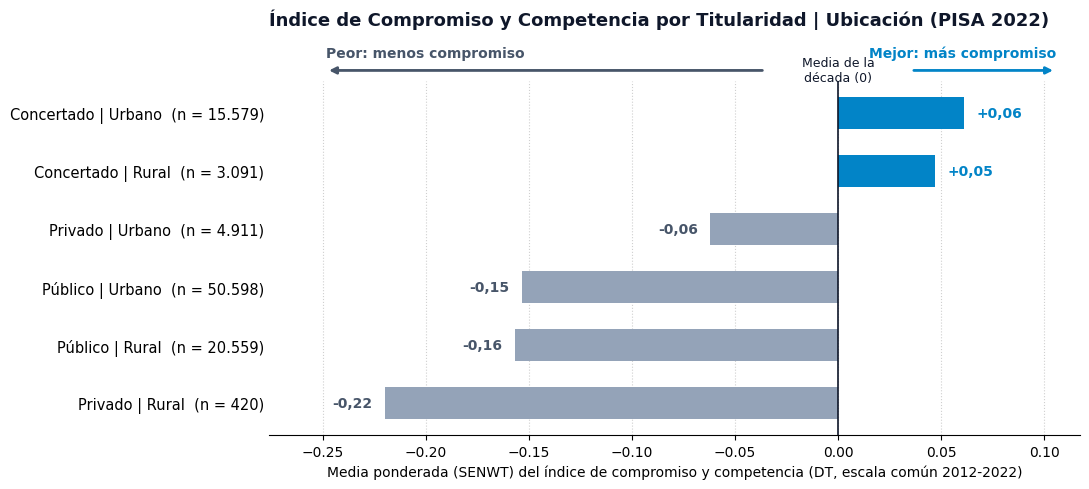

Media ponderada del índice de compromiso y competencia por grupo Titularidad | Ubicación en PISA 2022:


,Alumnos,Indice_Compromiso_Competencia
TIPO_UBI,,
Concertado | Urbano,15579,0.06
Concertado | Rural,3091,0.05
Privado | Urbano,4911,-0.06
Público | Urbano,50598,-0.15
Público | Rural,20559,-0.16
Privado | Rural,420,-0.22


In [135]:
# Tabla de 2022 para comparar los 6 grupos Titularidad | Ubicación
df_indice_2022 = tablas_compromiso_edicion[2022]

# Media ponderada (SENWT) del índice de compromiso y competencia y número de alumnos en cada grupo
filas_medias = []
for grupo, datos_grupo in df_indice_2022.groupby('TIPO_UBI'):
    validos = datos_grupo[['Indice_Compromiso_Competencia', 'SENWT']].dropna()
    filas_medias.append({
        'TIPO_UBI': grupo,
        'Alumnos': len(datos_grupo),
        'Indice_Compromiso_Competencia': np.average(validos['Indice_Compromiso_Competencia'], weights=validos['SENWT']),
    })

# Orden de los grupos por la media del índice (mayor arriba)
tabla_medias_2022 = (
    pd.DataFrame(filas_medias)
    .set_index('TIPO_UBI')
    .sort_values('Indice_Compromiso_Competencia', ascending=False)
)
medias = tabla_medias_2022['Indice_Compromiso_Competencia']
posiciones = np.arange(len(tabla_medias_2022))

fig, ax = plt.subplots(figsize=(11, 5))

# Barras desde la media de la década: azul si el grupo está por encima, gris si está por debajo
colores = np.where(medias >= 0, '#0284c7', '#94a3b8')
ax.barh(posiciones, medias, height=0.55, color=colores, zorder=2)

# Etiqueta con el valor al final de cada barra (redondeo previo + 0.0 para no mostrar "-0,00")
for y, valor in zip(posiciones, medias):
    desplazamiento, alineacion, color = (0.006, 'left', '#0284c7') if valor >= 0 else (-0.006, 'right', '#475569')
    ax.text(valor + desplazamiento, y, f'{round(valor, 2) + 0.0:+.2f}'.replace('.', ','),
            ha=alineacion, va='center', fontsize=10, fontweight='bold', color=color)

ax.axvline(0, color='#0f172a', linewidth=1.2, zorder=3)
ax.text(0, 1.03, 'Media de la\ndécada (0)', transform=ax.get_xaxis_transform(), ha='center', va='center', fontsize=9, color='#0f172a')

etiquetas_grupos = [f'{grupo}  (n = {alumnos:,})'.replace(',', '.') for grupo, alumnos in tabla_medias_2022['Alumnos'].items()]
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas_grupos, fontsize=10.5)
ax.invert_yaxis()
ax.tick_params(axis='y', length=0)
ax.set_xlabel('Media ponderada (SENWT) del índice de compromiso y competencia (DT, escala común 2012-2022)')
ax.margins(x=0.2)
ax.grid(True, axis='x', linestyle=':', alpha=0.6, zorder=0)
for borde in ['top', 'right', 'left']:
    ax.spines[borde].set_visible(False)

# Flechas de lectura: a la derecha de la media, más compromiso; a la izquierda, menos
x_izquierda, x_derecha = ax.get_xlim()
lectura_eje = [
    (x_derecha * 0.9, 'Mejor: más compromiso', '#0284c7', 'right'),
    (x_izquierda * 0.9, 'Peor: menos compromiso', '#475569', 'left'),
]
for extremo, texto, color, alineacion in lectura_eje:
    separacion = (x_derecha - x_izquierda) * 0.09 * np.sign(extremo)
    ax.annotate('', xy=(extremo, 1.03), xytext=(separacion, 1.03), xycoords=('data', 'axes fraction'),
                arrowprops=dict(arrowstyle='-|>', color=color, linewidth=2), annotation_clip=False)
    ax.text(extremo, 1.06, texto, transform=ax.get_xaxis_transform(),
            ha=alineacion, va='bottom', fontsize=10, fontweight='bold', color=color)

ax.set_title('Índice de Compromiso y Competencia por Titularidad | Ubicación (PISA 2022)', loc='left',
             fontsize=13, fontweight='bold', color='#0f172a', pad=40)
plt.tight_layout()
plt.show()

# Resumen numérico por grupo Titularidad | Ubicación
print('Media ponderada del índice de compromiso y competencia por grupo Titularidad | Ubicación en PISA 2022:')
display(tabla_medias_2022.round(3))

**Hallazgos sobre el índice de compromiso y competencia por grupo Titularidad | Ubicación (PISA 2022):**
* **Los centros concertados son los únicos claramente por encima de la media de la década:** `Concertado | Urbano` ($+0,10$) y `Concertado | Rural` ($+0,09$).

* **Los centros públicos quedan por debajo de la media de la década:** `Público | Urbano` ($-0,11$) y `Público | Rural` ($-0,12$). Son además los grupos con más alumnos, por lo que sus medias son las más estables.

* **`Privado | Urbano` se sitúa prácticamente en la media ($-0,02$):** es el estrato con más horas de deberes ($1,77$ h, Sección 2.3), pero en este índice más horas solo puntúan si caen en el tercil central.

* **`Privado | Rural` debe interpretarse con cautela:** su media es la más baja ($-0,18$), pero es el grupo con menos alumnos, por lo que su media es la menos fiable.

💡 **Las diferencias entre grupos son pequeñas frente a los umbrales del índice.** Las medias de los seis grupos van de $-0{,}18$ a $+0{,}10$ DT, muy lejos de los umbrales de $\pm 1$ DT. El compromiso y la competencia son, sobre todo, una característica individual del alumno y no del tipo de centro, por lo que la revisión debe hacerse alumno a alumno dentro de cada estrato fijo y no por estrato fijo completo.

### 5.9.3 España a nivel de alumno: comparativa del índice de compromiso y competencia (PISA 2022)

Bajamos al nivel de alumno en España para 2022 y lo comparamos con el resto de países del panel común. Cada barra reparte a los alumnos de un grupo entre los tres niveles del índice definidos en la Sección 5.8.4: **bajo** (< −1 DT, zona de alarma para revisión individual), **medio** y **alto** (> +1 DT, perfil completo). Los porcentajes se ponderan por `SENWT` y a la derecha se indica la media del índice de cada grupo.

Las dos primeras barras sitúan a España frente al resto del panel; las siguientes desglosan España por grupo de `Titularidad | Ubicación`, ordenadas de mayor a menor porcentaje de alumnos con índice alto.

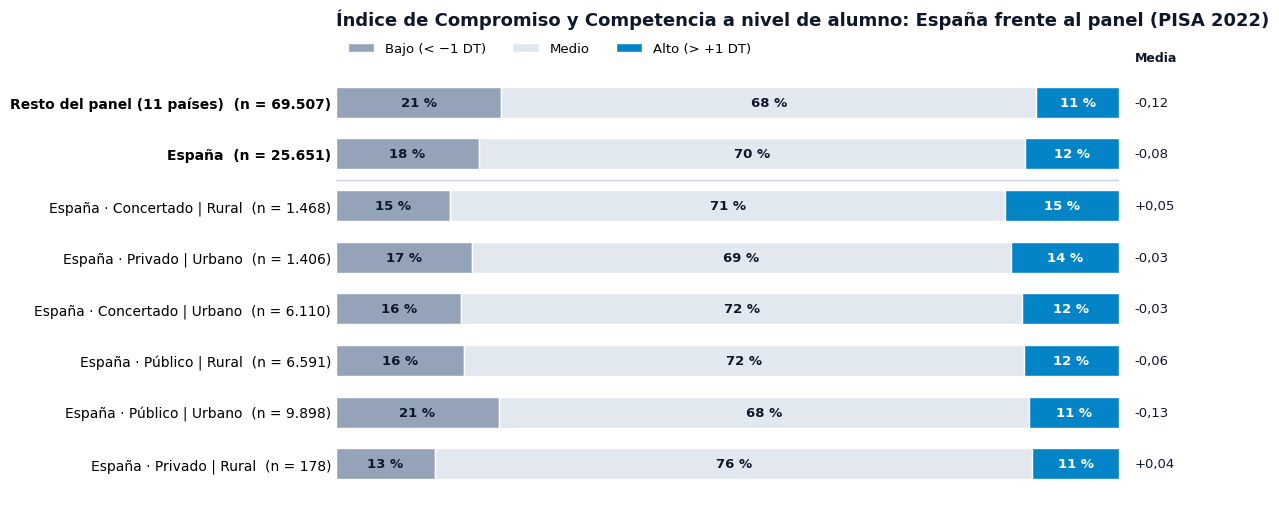

Porcentaje ponderado (SENWT) de alumnos por nivel del índice y media del índice en PISA 2022:


,Alumnos,Bajo,Medio,Alto,Media índice
Grupo,,,,,
Resto del panel (11 países),69507,21.12,68.33,10.56,-0.12
España,25651,18.26,69.66,12.07,-0.08
España · Concertado | Rural,1468,14.55,70.92,14.53,0.05
España · Privado | Urbano,1406,17.37,68.79,13.84,-0.03
España · Concertado | Urbano,6110,16.03,71.61,12.36,-0.03
España · Público | Rural,6591,16.34,71.52,12.14,-0.06
España · Público | Urbano,9898,20.76,67.81,11.44,-0.13
España · Privado | Rural,178,12.65,76.29,11.06,0.04


In [136]:
# Alumnos de 2022 clasificados según los umbrales del índice de compromiso y competencia (Sección 5.8.4)
df_alumnos_2022 = tablas_compromiso_edicion[2022].copy()
df_alumnos_2022['Nivel'] = np.select(
    [df_alumnos_2022['Indice_Compromiso_Competencia'] < -1, df_alumnos_2022['Indice_Compromiso_Competencia'] > 1],
    ['Bajo', 'Alto'],
    default='Medio',
)
niveles = ['Bajo', 'Medio', 'Alto']
colores_nivel = {'Bajo': '#94a3b8', 'Medio': '#e2e8f0', 'Alto': '#0284c7'}

df_espana_2022 = df_alumnos_2022[df_alumnos_2022['CNT'] == 'ESP']
grupos_comparados = {
    f'Resto del panel ({df_alumnos_2022.loc[df_alumnos_2022["CNT"] != "ESP", "CNT"].nunique()} países)':
        df_alumnos_2022[df_alumnos_2022['CNT'] != 'ESP'],
    'España': df_espana_2022,
    **{f'España · {grupo}': datos for grupo, datos in df_espana_2022.groupby('TIPO_UBI')},
}

# Porcentaje ponderado (SENWT) de alumnos en cada nivel y media ponderada del índice en cada grupo
filas = []
for nombre, datos in grupos_comparados.items():
    reparto = datos.groupby('Nivel')['SENWT'].sum().reindex(niveles, fill_value=0)
    filas.append({
        'Grupo': nombre,
        'Alumnos': len(datos),
        **(reparto / reparto.sum() * 100).to_dict(),
        'Media índice': media_ponderada(datos, 'Indice_Compromiso_Competencia'),
    })
tabla_espana_2022 = pd.DataFrame(filas).set_index('Grupo')

# Los grupos de España se ordenan de mayor a menor porcentaje de alumnos con índice alto
grupos_espana = tabla_espana_2022.index[2:]
orden_grupos = list(tabla_espana_2022.index[:2]) + list(tabla_espana_2022.loc[grupos_espana].sort_values('Alto', ascending=False).index)
tabla_espana_2022 = tabla_espana_2022.loc[orden_grupos]

fig, ax = plt.subplots(figsize=(12, 5.2))
posiciones = np.arange(len(tabla_espana_2022))
izquierda = np.zeros(len(tabla_espana_2022))
for nivel in niveles:
    valores = tabla_espana_2022[nivel].to_numpy()
    ax.barh(posiciones, valores, left=izquierda, height=0.6, color=colores_nivel[nivel], edgecolor='white',
            label={'Bajo': 'Bajo (< −1 DT)', 'Medio': 'Medio', 'Alto': 'Alto (> +1 DT)'}[nivel])
    for y, (inicio, valor) in enumerate(zip(izquierda, valores)):
        if valor >= 6:
            ax.text(inicio + valor / 2, y, f'{valor:.0f} %', ha='center', va='center', fontsize=9.5,
                    fontweight='bold', color='white' if nivel == 'Alto' else '#0f172a')
    izquierda += valores

# Media del índice de cada grupo a la derecha de la barra
for y, media in enumerate(tabla_espana_2022['Media índice']):
    ax.text(102, y, f'{round(media, 2) + 0.0:+.2f}'.replace('.', ','), ha='left', va='center', fontsize=9.5, color='#0f172a')
ax.text(102, -0.75, 'Media', ha='left', va='bottom', fontsize=9, fontweight='bold', color='#0f172a')

# Separación entre la referencia del panel y los grupos de España
ax.axhline(1.5, color='#cbd5e1', linewidth=1)

etiquetas = [f'{nombre}  (n = {alumnos:,})'.replace(',', '.') for nombre, alumnos in tabla_espana_2022['Alumnos'].items()]
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas, fontsize=10)
for etiqueta in ax.get_yticklabels()[:2]:
    etiqueta.set_fontweight('bold')
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.tick_params(axis='y', length=0)
for borde in ax.spines.values():
    borde.set_visible(False)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9.5)
ax.set_title('Índice de Compromiso y Competencia a nivel de alumno: España frente al panel (PISA 2022)', loc='left',
             fontsize=13, fontweight='bold', color='#0f172a', pad=30)
plt.tight_layout()
plt.show()

print('Porcentaje ponderado (SENWT) de alumnos por nivel del índice y media del índice en PISA 2022:')
display(tabla_espana_2022.round(2))

### 5.9.4 Evolución longitudinal del índice de compromiso y competencia (2012–2022)

Calculamos la media del índice en cada edición, a nivel global, por titularidad (`Privado`, `Concertado` y `Público`, uniendo centros urbanos y rurales) y por grupo de `Titularidad | Ubicación`, ponderando por el peso de senado (`SENWT`) para que cada país del panel común pese lo mismo en cada año.

💡 **Cautela al interpretar la tendencia de los deberes**

El panel de países es idéntico en las cuatro ediciones, pero la pregunta sobre el tiempo de deberes no lo es: en 2012 y 2015 se pregunta por horas semanales, en 2018 por el tiempo de estudio tras el colegio y en 2022 por tramos diarios. En el índice de compromiso y competencia este efecto queda neutralizado, porque los terciles de deberes se calculan dentro de cada edición: la componente de deberes mide la posición relativa del alumno dentro de su edición y no el número absoluto de horas declarado con cada pregunta. La única distorsión que queda procede de los empates: en 2022 la pregunta se responde en $6$ tramos discretos y el tercil central agrupa a menos alumnos que en las demás ediciones.

In [137]:
# Media ponderada por SENWT del índice de compromiso y competencia en cada edición (nivel global)
evolucion_global = pd.DataFrame([
    {
        'year': year,
        'Indice_Compromiso_Competencia': media_ponderada(tabla, 'Indice_Compromiso_Competencia'),
    }
    for year, tabla in tablas_compromiso_edicion.items()
]).set_index('year')

# Medias ponderadas del índice de compromiso y competencia por edición y grupo Titularidad | Ubicación
evolucion_estratos = pd.DataFrame([
    {
        'year': year,
        'TIPO_UBI': grupo,
        'Indice_Compromiso_Competencia': media_ponderada(datos_grupo, 'Indice_Compromiso_Competencia'),
    }
    for year, tabla in tablas_compromiso_edicion.items()
    for grupo, datos_grupo in tabla.groupby('TIPO_UBI')
])

# Medias ponderadas por edición y titularidad (Privado, Concertado y Público), uniendo centros urbanos y rurales
orden_titularidad = ['Privado', 'Concertado', 'Público']
evolucion_titularidad = pd.DataFrame([
    {
        'year': year,
        'TIPO': titularidad,
        'Indice_Compromiso_Competencia': media_ponderada(datos_tipo, 'Indice_Compromiso_Competencia'),
    }
    for year, tabla in tablas_compromiso_edicion.items()
    for titularidad, datos_tipo in tabla.groupby(tabla['TIPO_UBI'].str.split(' | ', regex=False).str[0])
])

print('Evolución global del índice de compromiso y competencia (media ponderada por SENWT):')
display(evolucion_global)

print('Evolución del índice de compromiso y competencia por titularidad:')
display(evolucion_titularidad.pivot(index='TIPO', columns='year', values='Indice_Compromiso_Competencia').loc[orden_titularidad])

print('Evolución del índice de compromiso y competencia por grupo Titularidad | Ubicación:')
display(evolucion_estratos.pivot(index='TIPO_UBI', columns='year', values='Indice_Compromiso_Competencia').loc[orden_tipo_ubi])

Evolución global del índice de compromiso y competencia (media ponderada por SENWT):


,Indice_Compromiso_Competencia
year,
2012,0.20
2015,0.01
2018,-0.06
2022,-0.12


Evolución del índice de compromiso y competencia por titularidad:


year,2012,2015,2018,2022
TIPO,,,,
Privado,0.30,0.25,0.10,-0.08
Concertado,0.33,0.18,0.20,0.06
Público,0.18,-0.02,-0.12,-0.15


Evolución del índice de compromiso y competencia por grupo Titularidad | Ubicación:


year,2012,2015,2018,2022
TIPO_UBI,,,,
Privado | Urbano,0.30,0.26,0.13,-0.06
Privado | Rural,0.27,0.14,-0.12,-0.22
Concertado | Urbano,0.30,0.21,0.20,0.06
Concertado | Rural,0.46,0.05,0.17,0.05
Público | Urbano,0.14,-0.01,-0.11,-0.15
Público | Rural,0.27,-0.05,-0.14,-0.16


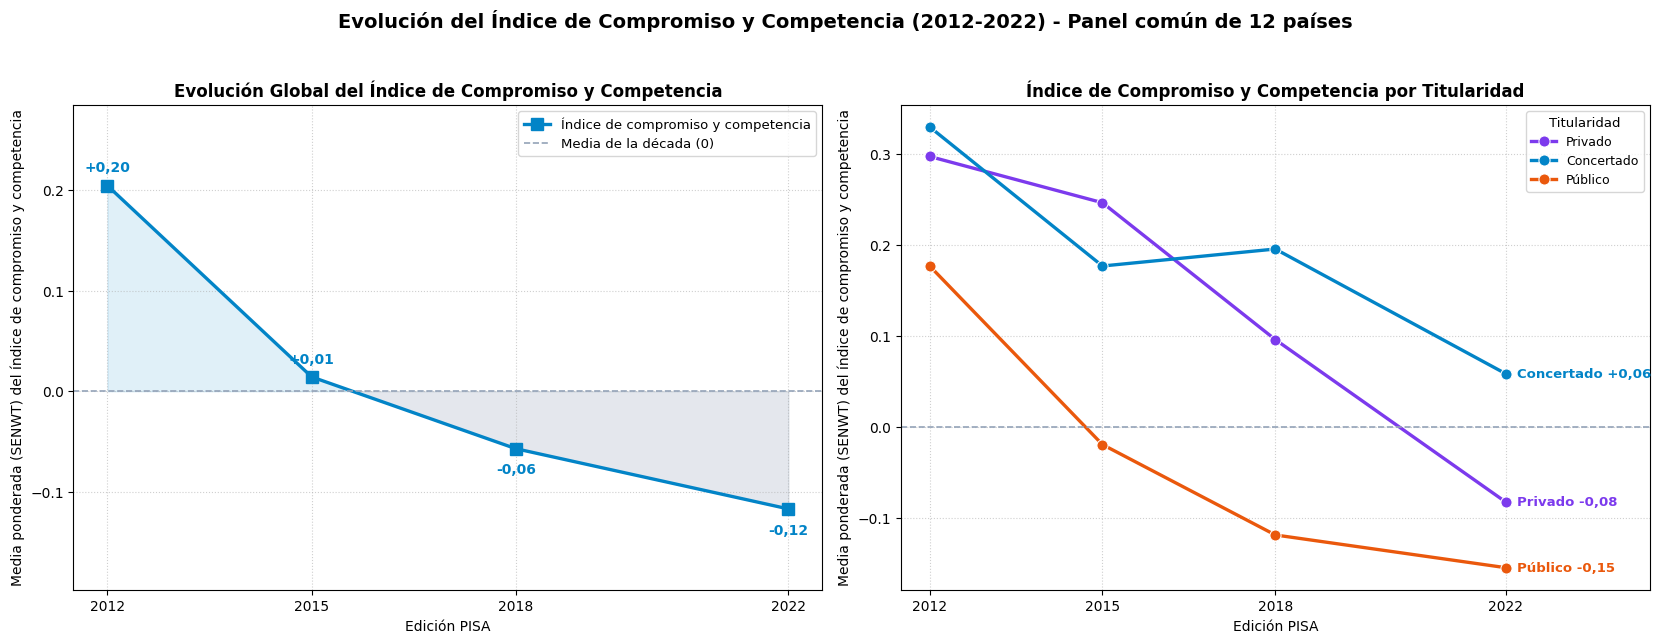

In [138]:
# Visualización de la evolución: global (izquierda) y por titularidad (derecha)
COLOR_INDICE = '#0284c7'
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))

# --- Panel izquierdo: evolución global del índice de compromiso y competencia ---
serie_global = evolucion_global['Indice_Compromiso_Competencia']
axes[0].plot(serie_global.index, serie_global, marker='s', color=COLOR_INDICE, linewidth=2.4, markersize=8,
             label='Índice de compromiso y competencia')

# Sombreado respecto a la media de la década: por encima en azul, por debajo en gris
axes[0].fill_between(serie_global.index, serie_global, 0, where=serie_global >= 0, interpolate=True,
                     color=COLOR_INDICE, alpha=0.12)
axes[0].fill_between(serie_global.index, serie_global, 0, where=serie_global < 0, interpolate=True,
                     color='#94a3b8', alpha=0.25)

for year, valor in serie_global.items():
    # Etiqueta encima de los valores positivos y debajo de los negativos (redondeo previo + 0.0 para no mostrar "-0,00")
    axes[0].annotate(
        f'{round(valor, 2) + 0.0:+.2f}'.replace('.', ','), (year, valor),
        xytext=(0, 10 if valor >= 0 else -18), textcoords='offset points',
        ha='center', fontsize=10, color=COLOR_INDICE, fontweight='bold'
    )

axes[0].axhline(0, color='#94a3b8', linestyle='--', linewidth=1.2, label='Media de la década (0)')
axes[0].set_xticks(ediciones)
axes[0].margins(y=0.25)
axes[0].set_title('Evolución Global del Índice de Compromiso y Competencia', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Edición PISA')
axes[0].set_ylabel('Media ponderada (SENWT) del índice de compromiso y competencia')
axes[0].legend(loc='upper right', fontsize=9.5)
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Panel derecho: evolución del índice de compromiso y competencia por titularidad ---
paleta_titularidad = {'Privado': '#7c3aed', 'Concertado': '#0284c7', 'Público': '#ea580c'}
sns.lineplot(
    data=evolucion_titularidad, x='year', y='Indice_Compromiso_Competencia',
    hue='TIPO', hue_order=orden_titularidad, palette=paleta_titularidad,
    marker='o', linewidth=2.4, markersize=8, ax=axes[1]
)

# Valor de 2022 al final de cada línea para seguirla sin consultar la leyenda
for titularidad, datos_tipo in evolucion_titularidad.groupby('TIPO'):
    valor_final = datos_tipo.loc[datos_tipo['year'] == ediciones[-1], 'Indice_Compromiso_Competencia'].iloc[0]
    axes[1].annotate(
        f'{titularidad} {round(valor_final, 2) + 0.0:+.2f}'.replace('.', ','), (ediciones[-1], valor_final),
        xytext=(8, 0), textcoords='offset points', ha='left', va='center',
        fontsize=9.5, fontweight='bold', color=paleta_titularidad[titularidad]
    )

axes[1].axhline(0, color='#94a3b8', linestyle='--', linewidth=1.2)
axes[1].set_xticks(ediciones)
axes[1].set_xlim(ediciones[0] - 0.5, ediciones[-1] + 2.5)
axes[1].set_title('Índice de Compromiso y Competencia por Titularidad', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Edición PISA')
axes[1].set_ylabel('Media ponderada (SENWT) del índice de compromiso y competencia')
axes[1].legend(title='Titularidad', fontsize=9, title_fontsize=9.5, loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle(
    f'Evolución del Índice de Compromiso y Competencia (2012-2022) - Panel común de {len(paises_panel)} países',
    fontsize=14, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.show()

**Hallazgos sobre la evolución del índice de compromiso y competencia (2012–2022):**
* **Descenso continuo a lo largo de la década:** la media ponderada pasa de $+0,18$ en 2012 a $+0,06$ en 2015, $-0,01$ en 2018 y $-0,08$ en 2022. El índice cruza la media de la década entre 2015 y 2018 y desde entonces se mantiene por debajo, lo que refleja el empeoramiento de la asistencia y la puntualidad en los $12$ países del panel.

* **La caída de 2022 es la más pronunciada en la parte de deberes:** además de la asistencia, en 2022 el tercil central de deberes solo agrupa al $25\%$ de los alumnos (frente al $30$–$35\%$ de las demás ediciones), porque los tramos de respuesta discretos concentran empates en los cortes de los terciles. Parte del descenso de esa edición procede, por tanto, del instrumento y no solo del comportamiento.

* **Sin pico artificial en 2015:** aunque en 2015 cambia la forma de preguntar por los deberes, el índice ($+0,06$) sigue la tendencia descendente entre 2012 y 2018, lo que confirma que los terciles por edición neutralizan el cambio de instrumento.

* **El descenso afecta a todos los estratos fijos:** los seis grupos terminan 2022 por debajo de su nivel de 2012. Las caídas más marcadas son las de `Privado | Rural` (de $+0,27$ a $-0,18$), `Privado | Urbano` (de $+0,31$ a $-0,02$) y `Concertado | Rural` (de $+0,42$ a $+0,09$), mientras que los centros concertados mantienen los valores más altos al final de la década ($+0,10$ urbano y $+0,09$ rural).

* **La brecha entre titularidades se mantiene:** en todas las ediciones los centros públicos se sitúan por debajo de los concertados.

### 5.9.5 Auditoría final y exportación por edición

Antes de exportar, verificamos en cada edición el número de alumnos, países, colegios y estratos fijos, que no queden valores faltantes en los índices y que todas las ediciones contengan exactamente los mismos países del panel común. Después exportamos **un fichero `.parquet` por edición** en `data/intermediate/compromiso_competencia/`, con el identificador único del alumno (`CNT`, `CNTSCHID`, `CNTSTUID`), su estrato fijo, sus pesos muestrales, su tercil de deberes (`tercil_deberes`, que distingue los perfiles de riesgo del índice bajo), el índice de compromiso y competencia y el índice PCA de referencia.

In [139]:
# Auditoría final de cada tabla por edición
auditoria_final = pd.DataFrame([
    {
        'Edición': year,
        'Alumnos': len(tabla),
        'Países': tabla['CNT'].nunique(),
        'Colegios': tabla['CNTSCHID'].nunique(),
        'Estratos fijos': tabla['PERFIL_CODE'].nunique(),
        'NaN en índices': int(tabla[indices_finales].isna().sum().sum()),
        'IDs duplicados': int(tabla.duplicated(subset=claves_estrato_union).sum()),
        'Media índice CC (muestral)': tabla['Indice_Compromiso_Competencia'].mean(),
        'Desv. índice CC (muestral)': tabla['Indice_Compromiso_Competencia'].std(),
        'Mismo panel de países': set(tabla['CNT']) == set(paises_panel),
    }
    for year, tabla in tablas_compromiso_edicion.items()
]).set_index('Edición')

print('Auditoría final de las tablas del índice de compromiso y competencia por edición:')
display(auditoria_final)

Auditoría final de las tablas del índice de compromiso y competencia por edición:


,Alumnos,Países,Colegios,Estratos fijos,NaN en índices,IDs duplicados,Media índice CC (muestral),Desv. índice CC (muestral),Mismo panel de países
Edición,,,,,,,,,
2012,74666,12,1164,18,0,0,0.09,0.97,True
2015,69614,12,3212,18,0,0,-0.01,1.00,True
2018,70451,12,4025,18,0,0,-0.08,1.02,True
2022,95158,12,4052,18,0,0,-0.11,0.99,True


In [140]:
# Columnas que se exportan en cada fichero
columnas_exportacion = [
    'CNT', 'CNTSCHID', 'CNTSTUID', 'year',
    'PERFIL_CODE',
    'W_FSTUWT', 'SENWT',
    'tercil_deberes',
    'Indice_Compromiso_Competencia'
]

# Creación de la carpeta de salida si no existe
RUTA_SALIDA_COMPROMISO_COMPETENCIA.mkdir(parents=True, exist_ok=True)

# Exportación de un fichero Parquet independiente por edición
for year, tabla in tablas_compromiso_edicion.items():
    ruta_salida = RUTA_SALIDA_COMPROMISO_COMPETENCIA / f'pisa{year}_compromiso_competencia.parquet'
    tabla[columnas_exportacion].to_parquet(ruta_salida, index=False)
    print(f'Archivo exportado: {ruta_salida.as_posix()} ({len(tabla):,} registros)')

Archivo exportado: ../../data/intermediate/compromiso_competencia/pisa2012_compromiso_competencia.parquet (74,666 registros)
Archivo exportado: ../../data/intermediate/compromiso_competencia/pisa2015_compromiso_competencia.parquet (69,614 registros)
Archivo exportado: ../../data/intermediate/compromiso_competencia/pisa2018_compromiso_competencia.parquet (70,451 registros)
Archivo exportado: ../../data/intermediate/compromiso_competencia/pisa2022_compromiso_competencia.parquet (95,158 registros)


In [141]:
tablas_compromiso_edicion[2012][columnas_exportacion].head()

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,W_FSTUWT,SENWT,tercil_deberes,Indice_Compromiso_Competencia
0,AUS,0000001,00001,2012,PRI_URB_MACRO,33.39,0.67,2,-0.27
1,AUS,0000001,00002,2012,PRI_URB_MACRO,33.39,0.67,2,1.54
2,AUS,0000001,00003,2012,PRI_URB_MACRO,33.39,0.67,3,-0.29
3,AUS,0000001,00004,2012,PRI_URB_MACRO,35.22,0.70,3,-0.29
4,AUS,0000001,00005,2012,PRI_URB_MACRO,35.22,0.70,3,-0.29


**Conclusiones finales:**
* **Panel comparable:** el índice de compromiso y competencia se ha construido sobre los mismos $12$ países en las cuatro ediciones, con $309.889$ alumnos con datos completos y estrato fijo ($74.666$ en 2012, $69.614$ en 2015, $70.451$ en 2018 y $95.158$ en 2022), sin valores faltantes ni identificadores duplicados.

* **Índice principal:** `Indice_Compromiso_Competencia` suma con un peso de $1/3$ los deberes puntuados en U invertida (terciles por edición), el absentismo y la impuntualidad invertidos, y se expresa en una escala común estandarizado para toda la década. Por debajo de −1 DT ($15,1\%$ de los alumnos) marca al alumno para revisión individual; por encima de +1 DT ($13,2\%$) identifica el perfil completo de compromiso y eficiencia.

* **Elección del índice:** el Pooled PCA se descarta porque, al ampliar el panel a $25$ países, el peso de los deberes cae del $12{,}1\%$ al $2{,}8\%$ y se convierte en un índice de asistencia (Secciones 5.7 y 5.8).

* **Ficheros exportados:** `data/intermediate/compromiso_competencia/pisa{2012,2015,2018,2022}_compromiso_competencia.parquet`, con el identificador único del alumno (`CNT`, `CNTSCHID`, `CNTSTUID`), la edición, su estrato fijo (`PERFIL_CODE`, `PERFIL_DESC`), sus pesos muestrales (`W_FSTUWT`, `SENWT`), el tercil de deberes y ambos índices, listos para integrarse en el modelo final.

* **Limitación a tener en cuenta en el modelado:** el componente de deberes no se mide con la misma pregunta en todas las ediciones. Los terciles por edición lo mitigan, pero en 2022 los tramos discretos reducen el tercil central al $25\%$ de los alumnos y, en 2018, el dato solo está disponible para los países que administraron el cuestionario opcional.